# HealthFlow Main Model
## NHS England Emergency Admissions Forecasting

A provider-level time-series workflow forecasting next-month total emergency admissions from official historical NHS England monthly A&E activity. Optional direct horizons of two and three months are prepared, while horizon one controls selection and deployment.

Operational uses include capacity, bed-demand, staffing, resource, scenario, and operational-risk planning. It is not an individual-patient model or an autonomous hospital decision system.

> **This model is intended solely for research and hospital operations capacity-planning demonstrations. It forecasts aggregate provider-level emergency admissions and must not be used for individual patient, clinical, diagnostic, triage or treatment decisions.**

Codex downloaded, validated, normalised, audited, and feature-engineered the data, but did not train, tune, evaluate, forecast with, select, or export any model.

## 1 — Configuration

In [1]:
from pathlib import Path
import os, sys, platform, json, time, importlib, hashlib
from datetime import datetime, timezone
import numpy as np
import pandas as pd

RANDOM_SEED = 42
BOOTSTRAP_SEED = 42
ALLOW_MODEL_TRAINING = True
ALLOW_MODEL_TUNING = True
ALLOW_FINAL_EVALUATION = True
ALLOW_MODEL_EXPORT = True
BENCHMARK_MODE = "full"  # quick, standard, full
N_JOBS = 20
TUNING_ITERATIONS = 25
TRAIN_TARGET_END = "2023-12"
VALIDATION_TARGET_START = "2024-01"
VALIDATION_TARGET_END = "2024-12"
TEST_TARGET_START = "2025-01"
TEST_TARGET_END = "latest"
MINIMUM_HISTORY_MONTHS = 24
MAXIMUM_MISSING_MONTH_FRACTION = .20
EXCLUDE_COVID_SENSITIVITY = False

def find_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "backend").is_dir():
            return candidate
    raise FileNotFoundError("Could not find repository root containing backend/.")

REPOSITORY_ROOT = find_root(Path.cwd())
BACKEND = REPOSITORY_ROOT / "backend"
RAW_DIR = BACKEND / "dataset/raw/nhs_england_ae/monthly"
PROCESSED_DIR = BACKEND / "dataset/processed/nhs_england_ae"
MANIFEST_DIR = BACKEND / "dataset/manifests"
ARTIFACT_DIR = BACKEND / "model_artifacts/emergency_admissions_forecast"
FIGURES_DIR = BACKEND / "reports/emergency_admissions_forecast/figures"
METRICS_DIR = BACKEND / "reports/emergency_admissions_forecast/metrics"
print("NHS England provider-month forecasting workflow:", REPOSITORY_ROOT)


NHS England provider-month forecasting workflow: F:\projhosp


## 2 — Environment validation

CPU is the default; no GPU is required.

In [2]:
import importlib.metadata as metadata
packages = ["pandas","pyarrow","numpy","scipy","scikit-learn","joblib","matplotlib",
 "jupyter","ipykernel","nbformat","nbclient","requests","tqdm","beautifulsoup4",
 "lxml","openpyxl","xlrd","xgboost","lightgbm","catboost","statsmodels","psutil"]
versions={}
for package in packages:
    try: versions[package]=metadata.version(package)
    except metadata.PackageNotFoundError: versions[package]="NOT INSTALLED"
try:
    import psutil
    ram_gib=round(psutil.virtual_memory().total/2**30,1)
except ImportError: ram_gib="unavailable"
print({"python":sys.version.split()[0],"os":platform.platform(),"cpus":os.cpu_count(),
       "ram_gib":ram_gib,"paths":{"raw":str(RAW_DIR),"processed":str(PROCESSED_DIR)}})
display(pd.Series(versions,name="version"))
for package in ("xgboost","lightgbm","catboost","statsmodels"):
    print(package, versions[package] != "NOT INSTALLED")


{'python': '3.13.12', 'os': 'Windows-11-10.0.26200-SP0', 'cpus': 28, 'ram_gib': 23.7, 'paths': {'raw': 'F:\\projhosp\\backend\\dataset\\raw\\nhs_england_ae\\monthly', 'processed': 'F:\\projhosp\\backend\\dataset\\processed\\nhs_england_ae'}}


pandas             3.0.5
pyarrow           25.0.0
numpy              2.5.1
scipy             1.18.0
scikit-learn       1.9.0
joblib             1.5.3
matplotlib        3.10.7
jupyter            1.1.1
ipykernel          7.1.0
nbformat          5.10.4
nbclient          0.10.2
requests          2.34.2
tqdm              4.69.1
beautifulsoup4    4.15.0
lxml               6.1.1
openpyxl           3.1.5
xlrd               2.0.2
xgboost            3.1.3
lightgbm           4.6.0
catboost           1.2.8
statsmodels       0.14.5
psutil             7.1.3
Name: version, dtype: str

xgboost True
lightgbm True
catboost True
statsmodels True


## 3 — Dataset discovery and manifest audit

In [3]:
download_manifest_path=MANIFEST_DIR/"nhs_ae_download_manifest.json"
if not download_manifest_path.exists():
    raise FileNotFoundError("Run: python backend/scripts/download_nhs_ae_dataset.py --start-month 2018-04 --end-month latest")
download_manifest=json.loads(download_manifest_path.read_text(encoding="utf-8"))
manifest_files=pd.DataFrame(download_manifest["files"])
display({"requested_range":[download_manifest["requested_start_month"],download_manifest["requested_end_month"]],
 "latest":download_manifest["latest_month_discovered"],"files":len(manifest_files),
 "missing":download_manifest["missing_months"],"revised":int(manifest_files.revised.sum()),
 "duplicates_rejected":len(download_manifest["duplicate_candidates_rejected"])})
display(manifest_files[["reporting_month","financial_year","revised","sha256",
                         "local_relative_path","source_url"]])


{'requested_range': ['2018-04', 'latest'],
 'latest': '2026-06',
 'files': 99,
 'missing': [],
 'revised': 88,
 'duplicates_rejected': 98}

,reporting_month,financial_year,revised,sha256,local_relative_path,source_url
0,2018-04,2018-19,True,49e785264a5228965e8856eef2fecc473a43da679f10d5...,backend/dataset/raw/nhs_england_ae/monthly/201...,https://www.england.nhs.uk/statistics/wp-conte...
1,2018-05,2018-19,True,82f5433b940ae6d65d4a861a0171dee327d637f413bd1e...,backend/dataset/raw/nhs_england_ae/monthly/201...,https://www.england.nhs.uk/statistics/wp-conte...
2,2018-06,2018-19,True,8e1365b31a34f60291a3728e6959b1c222d85951f93788...,backend/dataset/raw/nhs_england_ae/monthly/201...,https://www.england.nhs.uk/statistics/wp-conte...
3,2018-07,2018-19,True,af5c94824697bd36c2ce661c13c00d2d2d089408c05ee9...,backend/dataset/raw/nhs_england_ae/monthly/201...,https://www.england.nhs.uk/statistics/wp-conte...
4,2018-08,2018-19,True,4506920e1278e2fbf95f15164cda8e9320c54fd977be9f...,backend/dataset/raw/nhs_england_ae/monthly/201...,https://www.england.nhs.uk/statistics/wp-conte...
...,...,...,...,...,...,...
94,2026-02,2025-26,False,87f870535ea397d60645e9551672ece8d5193e2d6bc8e0...,backend/dataset/raw/nhs_england_ae/monthly/202...,https://www.england.nhs.uk/statistics/wp-conte...
95,2026-03,2025-26,True,5a6557670b5eb8d2f2999cecec9e61fca334d2e555ab5d...,backend/dataset/raw/nhs_england_ae/monthly/202...,https://www.england.nhs.uk/statistics/wp-conte...
96,2026-04,2026-27,False,09613a4478736c58d5a89bf2c9e1a5acb3d284d9da1b04...,backend/dataset/raw/nhs_england_ae/monthly/202...,https://www.england.nhs.uk/statistics/wp-conte...
97,2026-05,2026-27,False,9422af5fccfbac95902d94487a081396cb33e6d0331f3e...,backend/dataset/raw/nhs_england_ae/monthly/202...,https://www.england.nhs.uk/statistics/wp-conte...


## 4 — Raw schema audit

Mappings are explicit and file-specific. Unmapped required semantics stop preprocessing; no missing target is filled with zero.

In [4]:
schema_mapping=pd.read_csv(PROCESSED_DIR/"schema_mapping.csv")
schema_mapping["year"]=schema_mapping.reporting_month.str[:4]
display(schema_mapping.groupby(["year","mapping_status"]).size().unstack(fill_value=0))
display(schema_mapping[["reporting_month","source_file","original_column",
 "normalised_column","semantic_field","mapping_status"]])
display(schema_mapping[schema_mapping.mapping_status.ne("mapped")]
        .groupby("year").original_column.unique())


mapping_status,mapped,unmapped_nonrequired
year,,
2018,135,9
2019,180,12
2020,180,42
2021,181,90
2022,180,84
2023,180,84
2024,180,90
2025,180,84
2026,90,42


,reporting_month,source_file,original_column,normalised_column,semantic_field,mapping_status
0,2018-04,backend/dataset/raw/nhs_england_ae/monthly/201...,Period,period,reporting_period,mapped
1,2018-04,backend/dataset/raw/nhs_england_ae/monthly/201...,Org Code,org_code,provider_code,mapped
2,2018-04,backend/dataset/raw/nhs_england_ae/monthly/201...,Parent Org,parent_org,NaN,unmapped_nonrequired
3,2018-04,backend/dataset/raw/nhs_england_ae/monthly/201...,Org name,org_name,provider_name,mapped
4,2018-04,backend/dataset/raw/nhs_england_ae/monthly/201...,Number of A&E attendances Type 1,number_of_a_and_e_attendances_type_1,attendances_type_1,mapped
...,...,...,...,...,...,...
2018,2026-06,backend/dataset/raw/nhs_england_ae/monthly/202...,Patients who have waited 12+ hrs from DTA to a...,patients_who_have_waited_12_hrs_from_dta_to_ad...,dta_wait_over_12_hours,mapped
2019,2026-06,backend/dataset/raw/nhs_england_ae/monthly/202...,Emergency admissions via A&E - Type 1,emergency_admissions_via_a_and_e_type_1,admissions_type_1,mapped
2020,2026-06,backend/dataset/raw/nhs_england_ae/monthly/202...,Emergency admissions via A&E - Type 2,emergency_admissions_via_a_and_e_type_2,admissions_type_2,mapped
2021,2026-06,backend/dataset/raw/nhs_england_ae/monthly/202...,Emergency admissions via A&E - Other A&E depar...,emergency_admissions_via_a_and_e_other_a_and_e...,admissions_type_3,mapped


year
2018                                         [Parent Org]
2019                                         [Parent Org]
2020    [Parent Org, A&E attendances Booked Appointmen...
2021    [Parent Org, A&E attendances Booked Appointmen...
2022    [Parent Org, A&E attendances Booked Appointmen...
2023    [Parent Org, A&E attendances Booked Appointmen...
2024    [Parent Org, A&E attendances Booked Appointmen...
2025    [Parent Org, A&E attendances Booked Appointmen...
2026    [Parent Org, A&E attendances Booked Appointmen...
Name: original_column, dtype: object

## 5 — Normalised provider panel, filtering, A&E aggregation, and reconciliation

The preprocessing script separates national, regional/system, and invalid rows; keeps valid provider codes only; uses official all-type totals when present and otherwise sums mutually exclusive Type 1/2/3 components. Quarterly aggregates are excluded at discovery. Provider names are display-only.

In [5]:
panel=pd.read_parquet(PROCESSED_DIR/"provider_month_panel.parquet")
panel["reporting_month"]=pd.PeriodIndex(panel.reporting_month,freq="M")
continuity=pd.read_csv(PROCESSED_DIR/"provider_continuity_report.csv")
national=pd.read_csv(PROCESSED_DIR/"national_monthly_totals.csv")
quality=json.loads((PROCESSED_DIR/"data_quality_report.json").read_text())
print(panel.shape,panel.provider_code.nunique(),panel.reporting_month.min(),panel.reporting_month.max())
assert not panel.duplicated(["provider_code","reporting_month"]).any()
assert panel.provider_code.notna().all()
display(quality); display(continuity.describe(include="all"))


(17991, 11) 184 2018-04 2026-06


{'raw_rows': 21073,
 'provider_rows': 20794,
 'eligible_provider_rows': 17991,
 'negative_count_rows': 0,
 'duplicate_provider_months': 0,
 'missing_months': [],
 'excluded_row_classes': {'provider': 20794,
  'regional_or_system_total': 180,
  'national_total': 99},
 'warnings': []}

,provider_code,provider_name,first_reporting_month,last_reporting_month,months_present,provider_name_changes,months_missing,missing_month_fraction
count,279,279,279,279,279.000000,279.000000,279.000000,279.000000
unique,279,276,20,42,NaN,NaN,NaN,NaN
top,8J094,WHITSTABLE MEDICAL PRACTICE,2018-04,2026-06,NaN,NaN,NaN,NaN
freq,1,2,246,190,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,74.530466,1.878136,24.469534,0.247167
std,NaN,NaN,NaN,NaN,34.825025,0.611216,34.825025,0.351768
min,NaN,NaN,NaN,NaN,3.000000,1.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,41.500000,2.000000,0.000000,0.000000
50%,NaN,NaN,NaN,NaN,99.000000,2.000000,0.000000,0.000000
75%,NaN,NaN,NaN,NaN,99.000000,2.000000,57.500000,0.580808


## 6 — Data-quality and provider-continuity audit

Outliers are reported, not automatically deleted. Provider-code changes are never inferred from name similarity. Missing months remain missing rather than becoming false zeros.

In [6]:
counts=["total_ae_attendances","attendances_under_4_hours","emergency_admissions",
        "decision_to_admit_waits_over_4_hours"]
quality_table=pd.DataFrame({
 "missing":panel[counts].isna().sum(),"negative":(panel[counts]<0).sum(),
 "minimum":panel[counts].min(),"maximum":panel[counts].max()})
display(quality_table)
display(continuity.sort_values(["months_missing","provider_name_changes"],ascending=False).head(30))
changes=panel.sort_values(["provider_code","reporting_month"]).groupby("provider_code").emergency_admissions.pct_change(fill_method=None)
display(panel.loc[changes.abs().nlargest(30).index,
 ["provider_code","provider_name","reporting_month","emergency_admissions"]])


,missing,negative,minimum,maximum
total_ae_attendances,0,0,0.0,50421.0
attendances_under_4_hours,13,0,0.0,38876.0
emergency_admissions,0,0,0.0,19035.0
decision_to_admit_waits_over_4_hours,0,0,0.0,9496.0


,provider_code,provider_name,first_reporting_month,last_reporting_month,months_present,provider_name_changes,months_missing,missing_month_fraction
56,NNJ10,ENDERBY LEISURE CENTRE,2026-03,2026-06,3,1,96,0.969697
57,NNJ11,LUTTERWORTH HOSPITAL,2026-03,2026-06,3,1,96,0.969697
136,RGQ,IPSWICH HOSPITAL NHS TRUST,2018-04,2018-06,3,1,96,0.969697
152,RJF,BURTON HOSPITALS NHS FOUNDATION TRUST,2018-04,2018-06,3,1,96,0.969697
188,RR1,HEART OF ENGLAND NHS FOUNDATION TRUST,2018-04,2018-06,3,1,96,0.969697
260,Y02584,WALK IN CENTRE,2018-04,2018-06,3,1,96,0.969697
23,F84747,THE BARKANTINE PRACTICE,2018-04,2018-07,4,1,95,0.959596
47,NNF18,WITHERNSEA HOSPITAL,2018-04,2018-07,4,1,95,0.959596
48,NNF70,ALFRED BEAN HOSPITAL,2018-04,2018-07,4,1,95,0.959596
51,NNF99,HORNSEA COTTAGE HOSPITAL,2018-04,2018-07,4,1,95,0.959596


,provider_code,provider_name,reporting_month,emergency_admissions
10921,AJN,WORKINGTON HEALTH LIMITED,2023-04,400.0
11346,AJN,WORKINGTON HEALTH LIMITED,2023-06,555.0
203,C82009,MARKET HARBOROUGH MED.CTR,2018-05,338.0
1210,C83023,SLEAFORD MEDICAL GROUP,2018-10,4.0
5062,C83023,SLEAFORD MEDICAL GROUP,2020-08,4.0
6295,C83023,SLEAFORD MEDICAL GROUP,2021-02,1.0
10189,C83023,SLEAFORD MEDICAL GROUP,2022-12,5.0
12772,C83023,SLEAFORD MEDICAL GROUP,2024-02,8.0
14238,C83023,SLEAFORD MEDICAL GROUP,2024-10,1.0
15644,C83023,SLEAFORD MEDICAL GROUP,2025-05,2.0


## 7 — Exploratory analysis

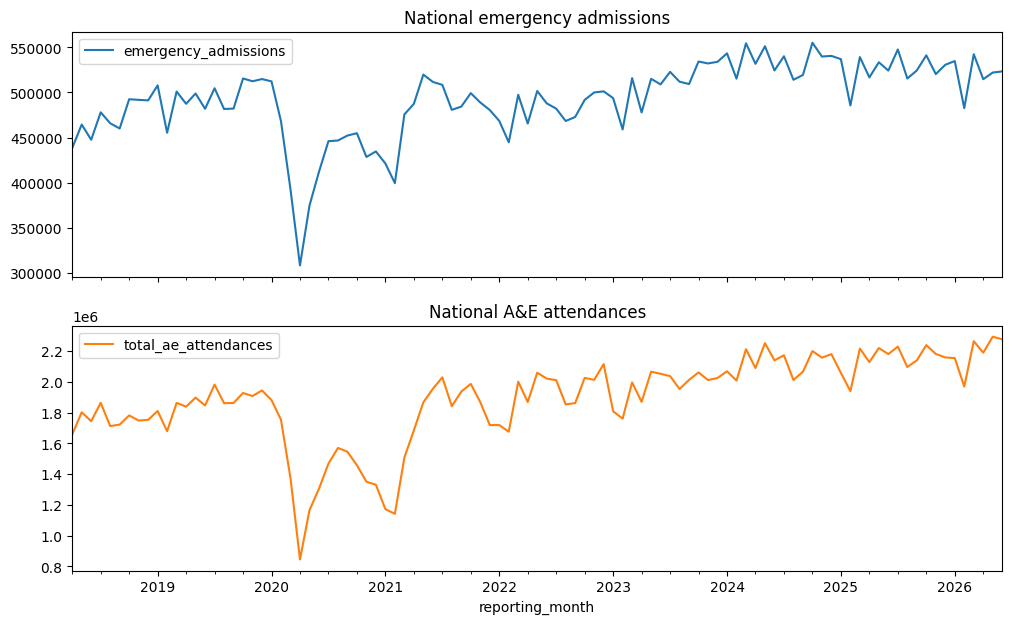

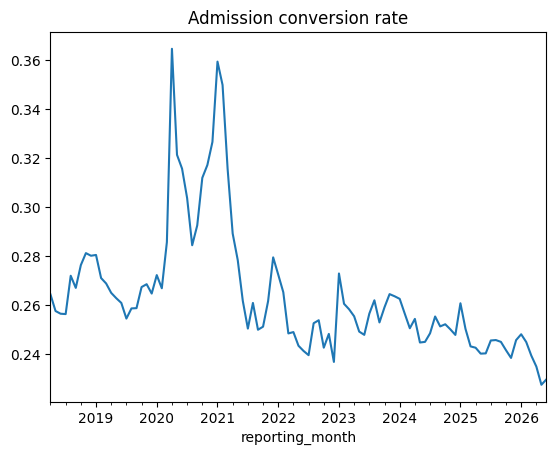

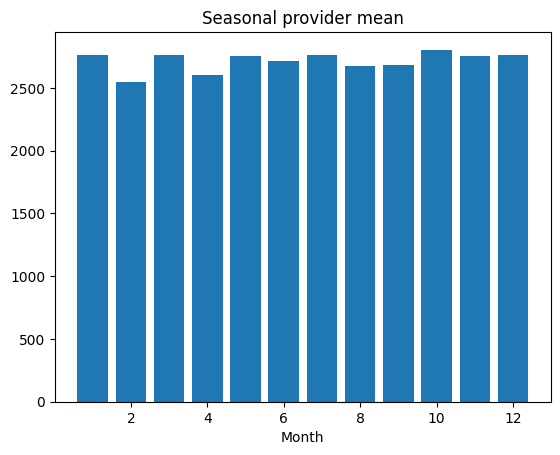

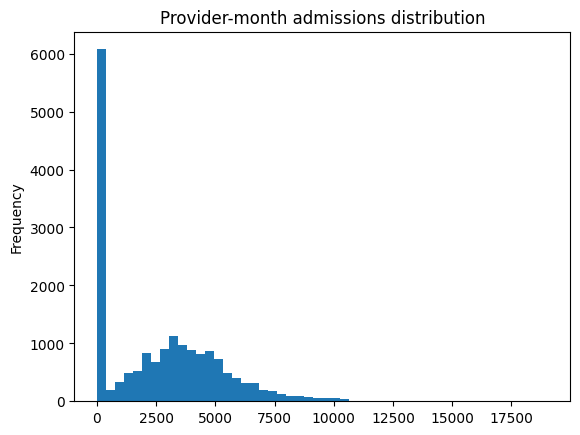

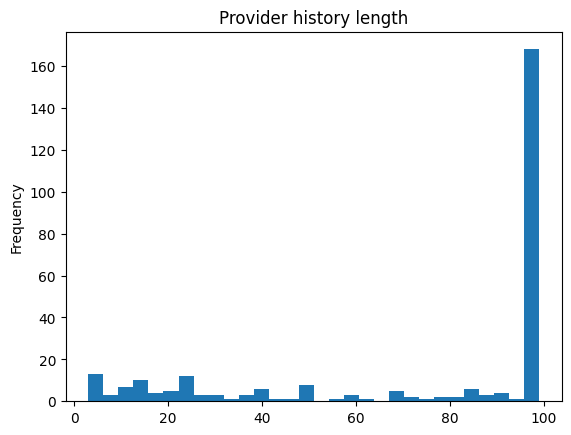

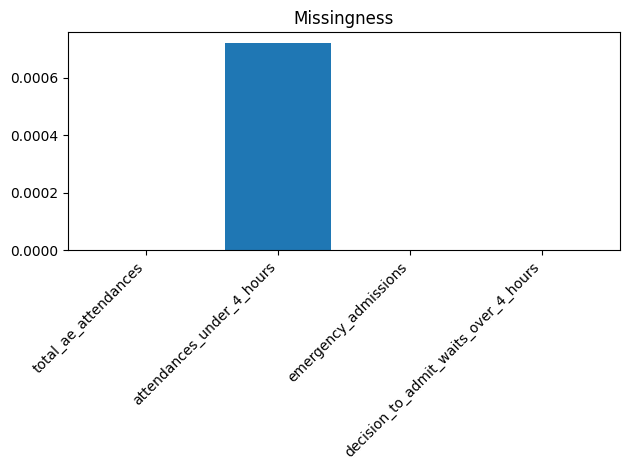

total_ae_attendances          attendances_under_4_hours  \
                                mean   median                      mean   
period                                                                    
disruption               7736.690371   6973.0               6728.314052   
post-disruption         11229.389885  10054.5               8240.239355   
pre-COVID               10161.795532   9457.5                8759.94609   

                        emergency_admissions          \
                 median                 mean  median   
period                                                 
disruption       5978.0          2369.593059  2280.0   
post-disruption  7108.0          2808.454271  2579.0   
pre-COVID        7964.5          2708.610733  2871.5   

                decision_to_admit_waits_over_4_hours         
                                                mean median  
period                                                       
disruption                                257.358625   74.0  
post-disruption                           700.769984  515.0  
pre-COVID                                 320.930792  131.5

provider_code  provider_name                                          
RRK            UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION TRUST       15015.44898
               University Hospitals Birmingham NHS Foundation Trust           14632.0
RAJ            Mid And South Essex NHS Foundation Trust                       11172.0
R0A            Manchester University NHS Foundation Trust                     10097.0
RAJ            MID AND SOUTH ESSEX NHS FOUNDATION TRUST                   9937.972973
R1H            Barts Health NHS Trust                                          9617.0
RYR            UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST           9256.677419
               University Hospitals Sussex NHS Foundation Trust                9127.0
RM3            NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST                8940.736842
RWE            UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST                 8546.05102
RBN            MERSEY AND WEST LANCASHIRE TEACHING HOSPITALS NHS TRUS

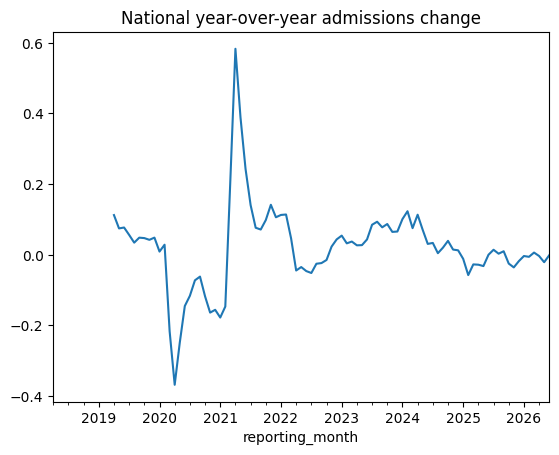

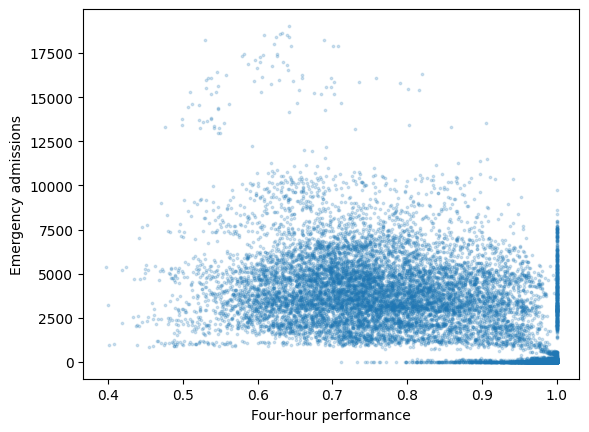

In [7]:
import matplotlib.pyplot as plt
monthly=panel.groupby("reporting_month")[counts].sum()
monthly.index=monthly.index.to_timestamp()
monthly[["emergency_admissions","total_ae_attendances"]].plot(subplots=True,figsize=(12,7),title=["National emergency admissions","National A&E attendances"]); plt.show()
(monthly.emergency_admissions/monthly.total_ae_attendances).plot(title="Admission conversion rate"); plt.show()
seasonal=panel.assign(month=panel.reporting_month.dt.month).groupby("month").emergency_admissions.mean()
plt.bar(seasonal.index.astype(int),seasonal.values);plt.title("Seasonal provider mean");plt.xlabel("Month");plt.show()
panel.emergency_admissions.plot.hist(bins=50,title="Provider-month admissions distribution"); plt.show()
continuity.months_present.plot.hist(bins=30,title="Provider history length"); plt.show()
missingness=panel[counts].isna().mean()
plt.bar(range(len(missingness)),missingness.values);plt.xticks(range(len(missingness)),missingness.index,rotation=45,ha="right");plt.title("Missingness");plt.tight_layout();plt.show()
period=np.select([panel.reporting_month<pd.Period("2020-03"),panel.reporting_month<=pd.Period("2021-06")],["pre-COVID","disruption"],default="post-disruption")
display(panel.assign(period=period).groupby("period")[counts].agg(["mean","median"]))
display(panel.groupby(["provider_code","provider_name"]).emergency_admissions.mean().nlargest(20))
yoy=monthly.emergency_admissions.pct_change(12); yoy.plot(title="National year-over-year admissions change"); plt.show()
plt.scatter(panel.attendances_under_4_hours/panel.total_ae_attendances,panel.emergency_admissions,s=3,alpha=.2)
plt.xlabel("Four-hour performance"); plt.ylabel("Emergency admissions"); plt.show()


## 8 — Leakage-safe forecasting features and targets

All lags are provider-wise. Rolling and historical provider statistics use `shift(1)` before aggregation. Targets h1/h2/h3 use chronological negative shifts. COVID disruption is retained in the primary analysis; sensitivity exclusion is configurable and never automatically preferred.

In [8]:
features=pd.read_parquet(PROCESSED_DIR/"forecasting_features.parquet")
features["reporting_month"]=pd.PeriodIndex(features.reporting_month,freq="M")
TARGET="target_emergency_admissions_h1"
OPTIONAL_TARGETS=["target_emergency_admissions_h2","target_emergency_admissions_h3"]
TARGETS=[TARGET,*OPTIONAL_TARGETS]
NON_FEATURES={"provider_name","reporting_month","feature_month","target_month","split",
              "emergency_admissions",*TARGETS,"source_file","source_url","ae_type",
              "row_class","financial_year"}
MODEL_FEATURES=[column for column in features.columns if column not in NON_FEATURES]
assert TARGET not in MODEL_FEATURES
assert not any(column.startswith("target_") for column in MODEL_FEATURES)
assert all(("rolling" not in c) or c.startswith(("admissions_rolling","attendances_rolling")) for c in MODEL_FEATURES)
display(pd.Series(MODEL_FEATURES,name="feature"))
display(features[TARGETS].describe())


0                            provider_code
1                     total_ae_attendances
2                attendances_under_4_hours
3     decision_to_admit_waits_over_4_hours
4                                     year
5                                    month
6                                  quarter
7                            days_in_month
8                              winter_flag
9                                month_sin
10                               month_cos
11                 covid_disruption_period
12              emergency_admissions_lag_1
13              emergency_admissions_lag_2
14              emergency_admissions_lag_3
15              emergency_admissions_lag_6
16             emergency_admissions_lag_12
17              total_ae_attendances_lag_1
18              total_ae_attendances_lag_2
19              total_ae_attendances_lag_3
20              total_ae_attendances_lag_6
21             total_ae_attendances_lag_12
22                waits_over_4_hours_lag_1
23         

,target_emergency_admissions_h1,target_emergency_admissions_h2,target_emergency_admissions_h3
count,17807.0,17623.0,17439.0
mean,2717.050486,2718.773762,2721.516371
std,2630.354627,2633.558951,2637.516254
min,0.0,0.0,0.0
25%,1.0,1.0,1.0
50%,2601.0,2598.0,2594.0
75%,4414.0,4414.0,4417.5
max,19035.0,19035.0,19035.0


## 9 — Chronological split and rolling-origin definitions

In [9]:
target_period=pd.PeriodIndex(features.target_month,freq="M")
features["split"]=np.select([
 target_period<=pd.Period(TRAIN_TARGET_END),
 (target_period>=pd.Period(VALIDATION_TARGET_START))&(target_period<=pd.Period(VALIDATION_TARGET_END)),
 target_period>=pd.Period(TEST_TARGET_START)],["train","validation","test"],default="unassigned")
if EXCLUDE_COVID_SENSITIVITY:
    features=features[features.covid_disruption_period.eq(0)].copy()
def split_report(frame):
    return frame.groupby("split").agg(feature_start=("feature_month","min"),feature_end=("feature_month","max"),
      target_start=("target_month","min"),target_end=("target_month","max"),
      providers=("provider_code","nunique"),rows=("provider_code","size"),
      missing_target=(TARGET,lambda x:x.isna().sum()),target_mean=(TARGET,"mean"),
      target_median=(TARGET,"median"),target_std=(TARGET,"std"))
display(split_report(features))
train=features[features.split.eq("train") & features[TARGET].notna()].copy()
validation=features[features.split.eq("validation") & features[TARGET].notna()].copy()
test=features[features.split.eq("test") & features[TARGET].notna()].copy()
assert pd.PeriodIndex(train.target_month,freq="M").max()<pd.PeriodIndex(validation.target_month,freq="M").min()
def rolling_origin_folds(frame,min_train_months=36,validation_months=3):
    periods=sorted(pd.PeriodIndex(frame.target_month,freq="M").unique())
    folds=[]
    for stop in range(min_train_months,len(periods)-validation_months+1,validation_months):
        train_end=periods[stop-1]; valid=periods[stop:stop+validation_months]
        folds.append((frame.index[pd.PeriodIndex(frame.target_month,freq="M")<=train_end],
                      frame.index[pd.PeriodIndex(frame.target_month,freq="M").isin(valid)]))
    return folds
ROLLING_FOLDS=rolling_origin_folds(train)
display(pd.DataFrame([{"fold":i+1,"train_end":train.loc[a,"target_month"].max(),
 "validation_start":train.loc[b,"target_month"].min(),"validation_end":train.loc[b,"target_month"].max()}
 for i,(a,b) in enumerate(ROLLING_FOLDS)]))


,feature_start,feature_end,target_start,target_end,providers,rows,missing_target,target_mean,target_median,target_std
split,,,,,,,,,,
test,2024-12,2026-06,2025-01,2026-07,184,3415,184,2920.766945,2456.0,2903.707992
train,2018-04,2023-11,2018-05,2023-12,184,12379,0,2626.6095,2625.0,2503.344271
validation,2023-12,2024-11,2024-01,2024-12,184,2197,0,2927.046427,2709.0,2867.750292


,fold,train_end,validation_start,validation_end
0,1,2021-04,2021-05,2021-07
1,2,2021-07,2021-08,2021-10
2,3,2021-10,2021-11,2022-01
3,4,2022-01,2022-02,2022-04
4,5,2022-04,2022-05,2022-07
5,6,2022-07,2022-08,2022-10
6,7,2022-10,2022-11,2023-01
7,8,2023-01,2023-02,2023-04
8,9,2023-04,2023-05,2023-07
9,10,2023-07,2023-08,2023-10


## 10 — Baselines and model pipelines

Counts remain continuous and non-negative. Raw predictions are preserved; clipped predictions are used for operational reporting, with negative counts reported.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.base import BaseEstimator,RegressorMixin
from sklearn.linear_model import LinearRegression,Ridge,ElasticNet
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor,GradientBoostingRegressor,HistGradientBoostingRegressor
class CatBoostRegressorAdapter(RegressorMixin,BaseEstimator):
    def __init__(self,iterations=400,depth=6,learning_rate=.04,verbose=False,
                 thread_count=-1,random_seed=42):
        self.iterations=iterations;self.depth=depth;self.learning_rate=learning_rate
        self.verbose=verbose;self.thread_count=thread_count;self.random_seed=random_seed
    def fit(self,X,y):
        from catboost import CatBoostRegressor
        self.estimator_=CatBoostRegressor(iterations=self.iterations,depth=self.depth,
          learning_rate=self.learning_rate,verbose=self.verbose,
          thread_count=self.thread_count,random_seed=self.random_seed)
        self.estimator_.fit(X,y)
        self.n_features_in_=X.shape[1]
        return self
    def predict(self,X):
        return self.estimator_.predict(X)
    @property
    def feature_importances_(self):
        return self.estimator_.feature_importances_
NUMERICAL=[c for c in MODEL_FEATURES if c!="provider_code"]; CATEGORICAL=["provider_code"]
def preprocessor(scale=False):
    num=[("impute",SimpleImputer(strategy="median",add_indicator=True))]
    if scale:num.append(("scale",StandardScaler()))
    return ColumnTransformer([("numeric",Pipeline(num),NUMERICAL),
      ("categorical",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),
       ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))]),CATEGORICAL)])
sizes={"quick":50,"standard":300,"full":800}
if BENCHMARK_MODE not in sizes: raise ValueError("BENCHMARK_MODE must be quick, standard, or full")
n_trees=sizes[BENCHMARK_MODE]
models={"Linear Regression":LinearRegression(),"Ridge Regression":Ridge(alpha=10),
 "Elastic Net":ElasticNet(alpha=.1,l1_ratio=.2,max_iter=5000,random_state=RANDOM_SEED),
 "Random Forest":RandomForestRegressor(n_estimators=n_trees,min_samples_leaf=3,n_jobs=N_JOBS,random_state=RANDOM_SEED),
 "Extra Trees":ExtraTreesRegressor(n_estimators=n_trees,min_samples_leaf=3,n_jobs=N_JOBS,random_state=RANDOM_SEED),
 "Gradient Boosting":GradientBoostingRegressor(n_estimators=200,learning_rate=.04,random_state=RANDOM_SEED),
 "Histogram Gradient Boosting":HistGradientBoostingRegressor(max_iter=250,learning_rate=.05,random_state=RANDOM_SEED)}
optional=[("XGBoost","xgboost","XGBRegressor",{"n_estimators":400,"learning_rate":.04,"n_jobs":N_JOBS,"random_state":RANDOM_SEED}),
 ("LightGBM","lightgbm","LGBMRegressor",{"n_estimators":400,"learning_rate":.04,"verbosity":-1,"n_jobs":N_JOBS,"random_state":RANDOM_SEED})]
availability={}
for name,module,cls_name,params in optional:
    try: models[name]=getattr(importlib.import_module(module),cls_name)(**params); availability[name]="available"
    except ImportError: availability[name]=f"unavailable; pip install -r {BACKEND/'requirements-ml.txt'}"
try:
    importlib.import_module("catboost")
    models["CatBoost"]=CatBoostRegressorAdapter(
      iterations=400,learning_rate=.04,verbose=False,
      thread_count=N_JOBS,random_seed=RANDOM_SEED)
    availability["CatBoost"]="available via scikit-learn compatibility adapter"
except ImportError:
    availability["CatBoost"]=f"unavailable; pip install -r {BACKEND/'requirements-ml.txt'}"
display(pd.Series(availability))
def baseline_predictions(frame):
    return {"Last-value naive":frame.emergency_admissions_lag_1,
      "Seasonal naive":frame.emergency_admissions_lag_12,
      "Three-month moving average":frame.admissions_rolling_mean_3,
      "Twelve-month moving average":frame.admissions_rolling_mean_12}


XGBoost                                            available
LightGBM                                           available
CatBoost    available via scikit-learn compatibility adapter
dtype: str

## 11 — Initial benchmarking

In [11]:
assert ALLOW_MODEL_TRAINING, (
    "Training is disabled. Manually set ALLOW_MODEL_TRAINING=True "
    "before executing this cell."
)
from sklearn.base import clone
X_train,y_train=train[MODEL_FEATURES],train[TARGET]
X_validation,y_validation=validation[MODEL_FEATURES],validation[TARGET]
fit_train=train
if BENCHMARK_MODE=="quick":
    chosen=np.random.default_rng(RANDOM_SEED).choice(train.provider_code.unique(),
      min(30,train.provider_code.nunique()),replace=False)
    fit_train=train[train.provider_code.isin(chosen)]
fitted_models={}; training_log={}; failures={}
for name,estimator in models.items():
    pipeline=Pipeline([("preprocess",preprocessor(name in {"Linear Regression","Ridge Regression","Elastic Net"})),
                       ("model",clone(estimator))])
    try:
        started=time.perf_counter(); pipeline.fit(fit_train[MODEL_FEATURES],fit_train[TARGET])
        training_log[name]={"training_seconds":time.perf_counter()-started,
                            "parameters":pipeline.get_params()}
        fitted_models[name]=pipeline
    except Exception as exc: failures[name]=repr(exc)
display(training_log); display(failures)
if not fitted_models:
    raise RuntimeError(
        "Every machine-learning model failed. Review the displayed failures "
        "before running validation or tuning."
    )


{'Linear Regression': {'training_seconds': 0.2463410999989719,
  'parameters': {'memory': None,
   'steps': [('preprocess',
     ColumnTransformer(transformers=[('numeric',
                                      Pipeline(steps=[('impute',
                                                       SimpleImputer(add_indicator=True,
                                                                     strategy='median')),
                                                      ('scale', StandardScaler())]),
                                      ['total_ae_attendances',
                                       'attendances_under_4_hours',
                                       'decision_to_admit_waits_over_4_hours',
                                       'year', 'month', 'quarter', 'days_in_month',
                                       'winter_flag', 'month_sin', 'month_cos',
                                       'covid_disruption_period',
                                       'em...
            

{}

## 12 — Validation metrics, outputs, and intervals

f:\projhosp\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


{}

,model,mae,median_ae,rmse,rmsle,r2,wape,smape,mase,bias,total_absolute_error,seasonal_naive_skill,negative_prediction_count,training_seconds,inference_milliseconds
7,Random Forest,139.004577,57.613835,274.666662,0.193901,0.990822,0.047490,0.097214,0.886188,27.007001,305393.055760,0.582689,0,18.459839,0.072582
8,Extra Trees,144.200974,57.335167,277.918765,0.280085,0.990604,0.049265,0.120046,0.919316,32.806891,316809.539894,0.567089,0,12.356968,0.092011
0,Last-value naive,145.821575,62.000000,269.108133,0.164098,0.991190,0.049819,0.066675,0.929648,6.472462,320370.000000,0.562224,0,0.000000,0.000000
2,Three-month moving average,148.488545,60.333333,272.439795,0.143420,0.990971,0.050730,0.063841,0.946651,14.357761,326229.333333,0.554217,0,0.000000,0.000000
12,LightGBM,152.806508,61.218151,296.065209,0.701864,0.989337,0.052205,0.360666,0.974179,34.544760,335715.897916,0.541254,266,0.839336,0.010648
10,Histogram Gradient Boosting,156.996217,63.192358,309.633870,0.769534,0.988337,0.053636,0.540820,1.000889,46.459583,344920.688281,0.528676,61,5.864609,0.010844
9,Gradient Boosting,159.485995,77.639664,303.252934,1.295374,0.988813,0.054487,0.488891,1.016762,45.412077,350390.730178,0.521201,167,22.039981,0.007737
11,XGBoost,160.802181,61.343262,312.922832,0.769269,0.988088,0.054937,0.422954,1.025153,49.632729,353282.391756,0.517250,190,2.860226,0.008337
5,Ridge Regression,165.016625,106.485254,260.712408,1.844666,0.991731,0.056376,0.442957,1.052021,-13.216031,362541.524410,0.504597,253,0.116084,0.005399
4,Linear Regression,167.042836,97.227548,274.968371,1.710702,0.990802,0.057069,0.403230,1.064939,-10.261714,366993.110201,0.498514,316,0.246341,0.005654


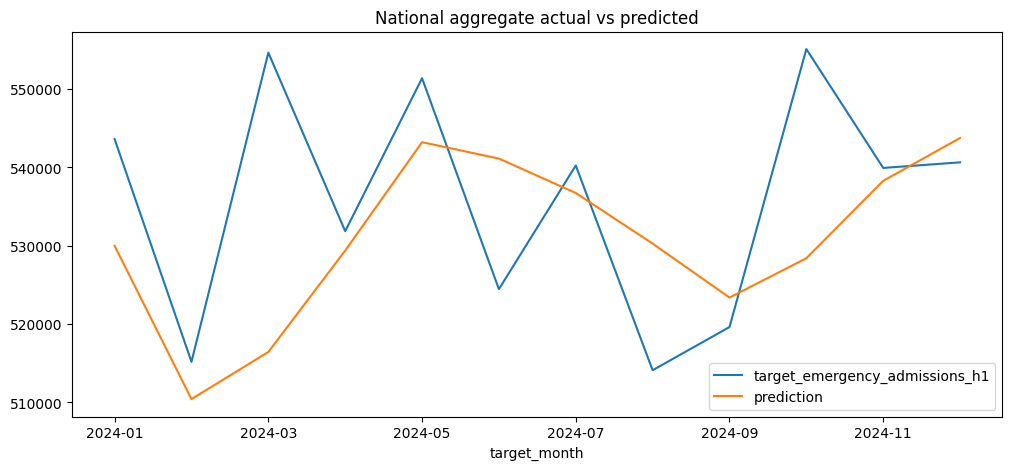

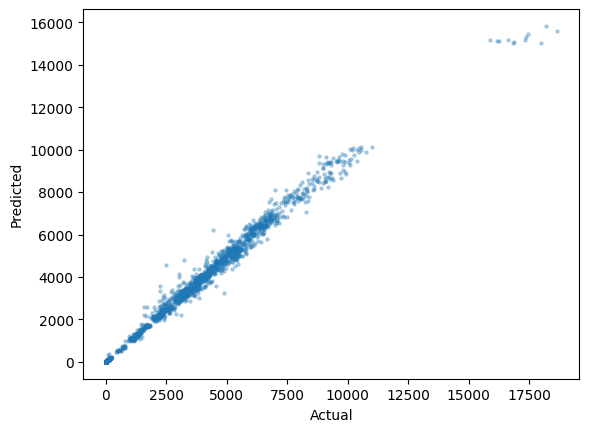

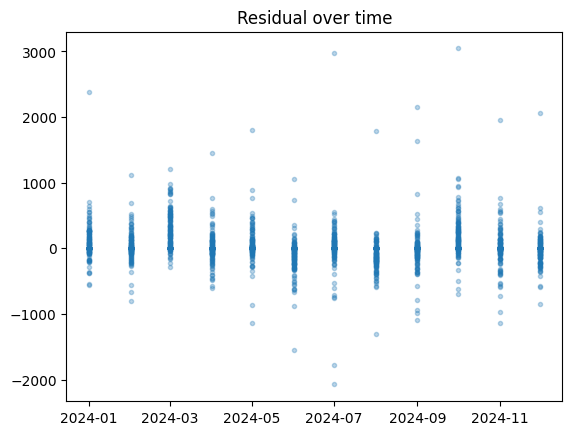

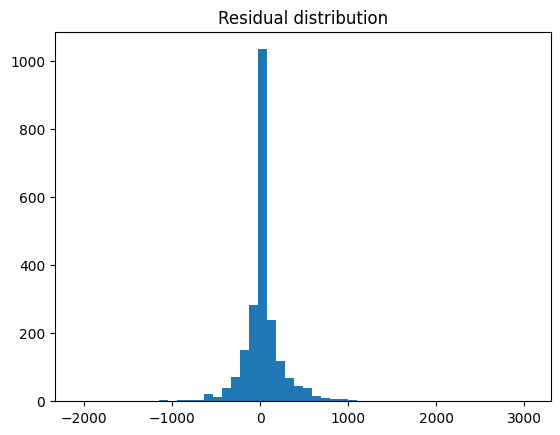

,mean,median
target_month,,
1,73.944118,0.000000
2,25.987183,0.000000
3,207.541222,95.065391
4,13.515745,0.000000
5,44.590784,0.000000
6,-91.043888,-28.905050
7,19.187371,0.000000
8,-88.296683,-42.041770
9,-20.533241,0.000000


80 coverage 0.7997269003186163
95 coverage 0.9499317250796541


In [12]:
assert ALLOW_MODEL_TRAINING, (
    "Training is disabled. Manually set ALLOW_MODEL_TRAINING=True "
    "before executing this cell."
)
from sklearn.metrics import mean_absolute_error,median_absolute_error,mean_squared_error,mean_squared_log_error,r2_score
if not fitted_models:
    raise RuntimeError(
        "No fitted ML models are available. Rerun the manual training cell "
        "and resolve its displayed failures first."
    )
def metrics(y,raw,seasonal,scale):
    pred=np.clip(raw,0,None); error=np.asarray(y)-pred
    denom=np.abs(y).sum(); smape=np.mean(2*np.abs(error)/(np.abs(y)+np.abs(pred)+1e-12))
    seasonal_wape=np.abs(np.asarray(y)-np.asarray(seasonal)).sum()/denom
    wape=np.abs(error).sum()/denom
    return {"mae":mean_absolute_error(y,pred),"median_ae":median_absolute_error(y,pred),
      "rmse":mean_squared_error(y,pred)**.5,"rmsle":mean_squared_log_error(y,pred)**.5,
      "r2":r2_score(y,pred),"wape":wape,"smape":smape,
      "mase":np.abs(error).mean()/scale,"bias":error.mean(),
      "total_absolute_error":np.abs(error).sum(),"seasonal_naive_skill":1-wape/seasonal_wape,
      "negative_prediction_count":int((np.asarray(raw)<0).sum())}
scale=train.groupby("provider_code").emergency_admissions.apply(lambda s:s.diff().abs().mean()).mean()
predictions={**baseline_predictions(validation)}
evaluation_failures={}
for name,pipeline in fitted_models.items():
    try:
        started=time.perf_counter(); raw=pipeline.predict(X_validation)
        training_log[name]["inference_milliseconds"]=1000*(time.perf_counter()-started)/len(validation)
        predictions[name]=raw
    except Exception as exc:
        evaluation_failures[name]=repr(exc)
display(evaluation_failures)
if not any(name in predictions for name in fitted_models):
    raise RuntimeError(
        "Every fitted ML model failed during validation prediction. "
        "Review evaluation_failures and rerun model definitions/training."
    )
rows=[]
for name,pred in predictions.items():
    valid=pd.Series(pred,index=validation.index).notna() & validation.emergency_admissions_lag_12.notna()
    row=metrics(y_validation[valid],np.asarray(pred)[valid],
                validation.loc[valid,"emergency_admissions_lag_12"],scale)
    rows.append({"model":name,**row,**training_log.get(name,{"training_seconds":0,"inference_milliseconds":0})})
benchmark_results=pd.DataFrame(rows).sort_values(["wape","mae","rmse", "bias"],key=lambda s:s.abs() if s.name=="bias" else s)
display(benchmark_results.drop(columns="parameters",errors="ignore"))
best_name=benchmark_results.iloc[0].model; best_raw=np.asarray(predictions[best_name]); best=np.clip(best_raw,0,None)
residual=y_validation.to_numpy()-best
validation["prediction"]=best
validation.groupby("target_month")[[TARGET,"prediction"]].sum().plot(figsize=(12,5),title="National aggregate actual vs predicted"); plt.show()
plt.scatter(y_validation,best,s=5,alpha=.3); plt.xlabel("Actual");plt.ylabel("Predicted");plt.show()
plt.plot(pd.PeriodIndex(validation.target_month,freq="M").to_timestamp(),residual,".",alpha=.3);plt.title("Residual over time");plt.show()
plt.hist(residual,bins=50);plt.title("Residual distribution");plt.show()
display(validation.assign(error=residual).groupby(pd.PeriodIndex(validation.target_month,freq="M").month).error.agg(["mean","median"]))
q80=np.quantile(residual,[.10,.90]);q95=np.quantile(residual,[.025,.975])
validation_intervals={"80":q80.tolist(),"95":q95.tolist()}
for level,q in validation_intervals.items():
    lower=np.clip(best+q[0],0,None);upper=best+q[1]
    print(level,"coverage",np.mean((y_validation>=lower)&(y_validation<=upper)))


## 13 — Rolling-origin tuning

In [13]:
assert ALLOW_MODEL_TUNING, (
    "Tuning is disabled. Manually set ALLOW_MODEL_TUNING=True "
    "before executing this cell."
)
from sklearn.model_selection import ParameterSampler
successful_ml_results=benchmark_results[benchmark_results.model.isin(fitted_models)].copy()
if successful_ml_results.empty:
    raise RuntimeError(
        "Benchmark results contain no successfully fitted ML model. "
        "Rerun training and validation after resolving model failures."
    )
top_three=successful_ml_results.head(3).model.tolist()
search_spaces={"Random Forest":{"model__max_depth":[None,8,14],"model__min_samples_leaf":[2,4,8]},
 "Extra Trees":{"model__max_depth":[None,8,14],"model__min_samples_leaf":[2,4,8]},
 "Gradient Boosting":{"model__n_estimators":[100,200,400],"model__learning_rate":[.02,.05,.1]},
 "Histogram Gradient Boosting":{"model__max_leaf_nodes":[15,31,63],"model__learning_rate":[.02,.05,.1]},
 "XGBoost":{"model__n_estimators":[200,400,700],"model__max_depth":[3,6,9],"model__learning_rate":[.02,.05,.1]},
 "LightGBM":{"model__n_estimators":[200,400,700],"model__num_leaves":[15,31,63],"model__learning_rate":[.02,.05,.1]},
 "CatBoost":{"model__iterations":[200,400,700],"model__depth":[4,7,10],"model__learning_rate":[.02,.05,.1]},
 "Ridge Regression":{"model__alpha":[.1,1,10,100,1000]},
 "Elastic Net":{"model__alpha":[.001,.01,.1,1],"model__l1_ratio":[.1,.3,.5,.8]},
 "Linear Regression":{"model__fit_intercept":[True,False]}}
tuning_results=[]; tuned_models={}
for name in top_three:
    space=search_spaces.get(name)
    if not space: continue
    for params in ParameterSampler(space,n_iter=min(TUNING_ITERATIONS,9),random_state=RANDOM_SEED):
        fold_scores=[]
        for train_idx,valid_idx in ROLLING_FOLDS:
            candidate=clone(fitted_models[name]).set_params(**params)
            candidate.fit(train.loc[train_idx,MODEL_FEATURES],train.loc[train_idx,TARGET])
            raw=candidate.predict(train.loc[valid_idx,MODEL_FEATURES])
            fold_scores.append(np.abs(train.loc[valid_idx,TARGET]-np.clip(raw,0,None)).sum()/train.loc[valid_idx,TARGET].abs().sum())
        tuning_results.append({"model":name,"params":params,"rolling_wape":np.mean(fold_scores)})
tuning_results=pd.DataFrame(tuning_results)
if tuning_results.empty:
    raise RuntimeError(
        f"No tuning candidates were generated for top models {top_three}. "
        f"Available search spaces: {sorted(search_spaces)}"
    )
tuning_results=tuning_results.sort_values("rolling_wape")
display(tuning_results)
for name in top_three:
    candidates=tuning_results[tuning_results.model.eq(name)]
    if not candidates.empty:
        tuned=clone(fitted_models[name]).set_params(**candidates.iloc[0].params)
        tuned.fit(X_train,y_train); tuned_models[name]=tuned


f:\projhosp\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
f:\projhosp\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
f:\projhosp\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
f:\projhosp\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
f:\projhosp\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
f:\projhosp\.venv\Lib\site-packages\sklearn\utils\validation.py:2827: UserW

,model,params,rolling_wape
19,LightGBM,"{'model__num_leaves': 31, 'model__n_estimators...",0.047752
24,LightGBM,"{'model__num_leaves': 31, 'model__n_estimators...",0.048198
26,LightGBM,"{'model__num_leaves': 15, 'model__n_estimators...",0.048243
23,LightGBM,"{'model__num_leaves': 63, 'model__n_estimators...",0.048737
18,LightGBM,"{'model__num_leaves': 63, 'model__n_estimators...",0.048753
20,LightGBM,"{'model__num_leaves': 15, 'model__n_estimators...",0.048792
21,LightGBM,"{'model__num_leaves': 15, 'model__n_estimators...",0.049398
25,LightGBM,"{'model__num_leaves': 63, 'model__n_estimators...",0.049828
9,Extra Trees,"{'model__min_samples_leaf': 2, 'model__max_dep...",0.050143
10,Extra Trees,"{'model__min_samples_leaf': 4, 'model__max_dep...",0.050496


## 14 — Final test protocol, residual diagnostics, provider errors, bootstrap, and feature importance

In [14]:
assert ALLOW_FINAL_EVALUATION, (
    "Final evaluation is disabled. Manually set ALLOW_FINAL_EVALUATION=True "
    "before executing this cell."
)
from sklearn.inspection import permutation_importance
successful_ml_results=benchmark_results[benchmark_results.model.isin(fitted_models)]
if successful_ml_results.empty:
    raise RuntimeError("No fitted ML candidate is available for final evaluation.")
selected_model_name=successful_ml_results.iloc[0].model
final_model=tuned_models.get(selected_model_name,fitted_models.get(selected_model_name))
if final_model is None: raise RuntimeError("Selected candidate is not a trained ML pipeline.")
raw_test=final_model.predict(test[MODEL_FEATURES]); clipped_test=np.clip(raw_test,0,None)
valid=test.emergency_admissions_lag_12.notna()
test_metrics=metrics(test.loc[valid,TARGET],raw_test[valid],test.loc[valid,"emergency_admissions_lag_12"],scale)
test_errors=test.loc[valid,["provider_code","provider_name","target_month",TARGET]].copy()
test_errors["prediction"]=clipped_test[valid];test_errors["error"]=test_errors[TARGET]-test_errors.prediction
provider_error_metrics=test_errors.groupby(["provider_code","provider_name"]).agg(
 rows=("error","size"),mae=("error",lambda x:x.abs().mean()),bias=("error","mean")).reset_index()
display(test_metrics);display(provider_error_metrics.nlargest(10,"mae"));display(provider_error_metrics.nsmallest(10,"mae"))
display(test_errors.groupby("target_month").error.agg(["mean","median"]))
test_errors["volume_quartile"]=pd.qcut(test_errors[TARGET],4,duplicates="drop")
display(test_errors.groupby("volume_quartile",observed=True).error.agg(["mean","median"]))
for level,q in validation_intervals.items():
    lower=np.clip(clipped_test+q[0],0,None);upper=clipped_test+q[1]
    test_metrics[f"interval_{level}_coverage"]=np.mean((test[TARGET]>=lower)&(test[TARGET]<=upper))
rng=np.random.default_rng(BOOTSTRAP_SEED);providers=test_errors.provider_code.unique();boot=[]
for _ in range(1000):
    sampled=rng.choice(providers,len(providers),replace=True)
    blocks=pd.concat([test_errors[test_errors.provider_code.eq(code)] for code in sampled])
    boot.append(metrics(blocks[TARGET],blocks.prediction,
      np.maximum(blocks[TARGET]-blocks.error,0),scale))
bootstrap_ci={key:np.quantile([row[key] for row in boot],[.025,.975]).tolist()
              for key in ["mae","rmse","wape","smape"]}
display(bootstrap_ci)
sample=validation.sample(min(3000,len(validation)),random_state=RANDOM_SEED)
importance=permutation_importance(final_model,sample[MODEL_FEATURES],sample[TARGET],
 scoring="neg_mean_absolute_error",n_repeats=8,random_state=RANDOM_SEED,n_jobs=N_JOBS)
feature_importance=pd.DataFrame({"feature":MODEL_FEATURES,
 "importance_mean":importance.importances_mean,"importance_std":importance.importances_std}).sort_values("importance_mean",ascending=False)
display(feature_importance)


{'mae': 155.29548053462844,
 'median_ae': 59.80307600242668,
 'rmse': 347.923383803578,
 'rmsle': 0.2635790735909304,
 'r2': 0.9856386325914942,
 'wape': np.float64(0.05316941866548923),
 'smape': np.float64(0.12266094114343329),
 'mase': np.float64(0.990046560687439),
 'bias': np.float64(6.44755218745174),
 'total_absolute_error': np.float64(501759.6976073845),
 'seasonal_naive_skill': np.float64(0.5077993315741145),
 'negative_prediction_count': 0}

,provider_code,provider_name,rows,mae,bias
127,RRK,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,18,2752.028285,2752.028285
178,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,18,824.274933,770.745858
148,RWE,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST,18,822.551852,801.666855
101,RL4,THE ROYAL WOLVERHAMPTON NHS TRUST,18,589.37064,139.579627
159,RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,18,588.111676,289.915827
40,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,18,525.414964,326.424901
70,RF4,"BARKING, HAVERING AND REDBRIDGE UNIVERSITY HOS...",18,496.147093,-231.122134
149,RWF,MAIDSTONE AND TUNBRIDGE WELLS NHS TRUST,18,489.70026,-362.46171
41,RAL,ROYAL FREE LONDON NHS FOUNDATION TRUST,18,465.00303,140.991203
49,RBN,MERSEY AND WEST LANCASHIRE TEACHING HOSPITALS ...,18,454.868945,103.177267


,provider_code,provider_name,rows,mae,bias
0,8J094,BADGER LTD,15,0.0,0.0
1,AAH,TETBURY HOSPITAL TRUST LTD,18,0.0,0.0
4,AQN04,PHL LYMINGTON UTC,18,0.0,0.0
5,AXG,WILTSHIRE HEALTH & CARE,2,0.0,0.0
6,C82009,MARKET HARBOROUGH MED.CTR,17,0.0,0.0
7,C82038,LATHAM HOUSE MEDICAL PRACTICE,18,0.0,0.0
10,L83087,OKEHAMPTON MEDICAL CENTRE,18,0.0,0.0
11,NDJ,FIRST COMMUNITY HEALTH AND CARE CIC,18,0.0,0.0
12,NL7,ASSURA VERTIS URGENT CARE CENTRES (BIRMINGHAM),15,0.0,0.0
13,NNF09,BRANSHOLME HEALTH CENTRE,18,0.0,0.0


,mean,median
target_month,,
2025-01,9.443324,0.0
2025-02,-140.844879,-84.227662
2025-03,130.705911,8.14466
2025-04,-18.004764,0.0
2025-05,30.368376,0.0
2025-06,-2.72934,0.0
2025-07,109.810125,2.548984
2025-08,-93.274624,-34.081097
2025-09,4.269547,0.0


,mean,median
volume_quartile,,
"(-0.001, 1.0]",-0.374121,0.0
"(1.0, 2456.0]",-29.164103,-3.363026
"(2456.0, 4833.5]",-48.16325,-36.304526
"(4833.5, 19035.0]",103.163281,32.610383


{'mae': [124.71866660656252, 194.18058101634057],
 'rmse': [241.6832677481959, 481.02096545107247],
 'wape': [0.04681976171097748, 0.062051295928334096],
 'smape': [0.08201693253111557, 0.16850983987271417]}

,feature,importance_mean,importance_std
12,emergency_admissions_lag_1,2.571829e+03,2.914435e+01
46,provider_historical_median,1.214069e+02,2.237894e+00
44,provider_historical_mean,5.405450e+01,1.040444e+00
0,provider_code,2.617516e+01,1.953249e+00
3,decision_to_admit_waits_over_4_hours,1.667646e+01,1.010368e+00
38,admissions_change_1,1.554037e+01,1.198754e+00
1,total_ae_attendances,1.189369e+01,1.023453e+00
40,admissions_growth_rate_1,9.833811e+00,1.234196e+00
32,admissions_rolling_mean_6,4.571935e+00,5.910732e-01
9,month_sin,3.755020e+00,4.032670e-01


## 15 — Final model-selection report

Primary metric is validation WAPE. Tie-breakers are MAE, RMSE, absolute bias, seasonal-naive skill, provider stability, latency, then simplicity. A complex model should not deploy unless it reliably beats seasonal naive.

In [15]:
assert ALLOW_FINAL_EVALUATION, (
    "Final evaluation is disabled. Manually set ALLOW_FINAL_EVALUATION=True "
    "before executing this cell."
)
selection=benchmark_results.rename(columns={"wape":"validation_wape","mae":"validation_mae",
 "rmse":"validation_rmse","smape":"validation_smape","mase":"validation_mase",
 "bias":"validation_bias"})[["model","validation_wape","validation_mae","validation_rmse",
 "validation_smape","validation_mase","validation_bias","seasonal_naive_skill",
 "training_seconds","inference_milliseconds","negative_prediction_count"]].copy()
deployable=selection[selection.model.isin(fitted_models)].copy()
eligible=deployable[deployable.seasonal_naive_skill>0]
if eligible.empty:
    raise RuntimeError(
        "No fitted ML model reliably beats seasonal naive on validation WAPE. "
        "Do not export a complex model; review features and validation design."
    )
recommended=eligible.sort_values(["validation_wape","validation_mae","validation_rmse"]).iloc[0].model
MODEL_OVERRIDE=None;MODEL_OVERRIDE_REASON=""
if MODEL_OVERRIDE:
    if MODEL_OVERRIDE not in fitted_models:
        raise ValueError("MODEL_OVERRIDE must name a successfully fitted ML pipeline.")
    if MODEL_OVERRIDE_REASON.strip()=="":raise ValueError("Document MODEL_OVERRIDE_REASON.")
    recommended=MODEL_OVERRIDE
selection["selected"]=selection.model.eq(recommended)
selection["selection_reason"]=np.where(selection.selected,
 MODEL_OVERRIDE_REASON or "Best validation WAPE under baseline-skill and tie-break policy","Not selected")
selected_model_name=recommended
display(selection)


,model,validation_wape,validation_mae,validation_rmse,validation_smape,validation_mase,validation_bias,seasonal_naive_skill,training_seconds,inference_milliseconds,negative_prediction_count,selected,selection_reason
7,Random Forest,0.047490,139.004577,274.666662,0.097214,0.886188,27.007001,0.582689,18.459839,0.072582,0,True,Best validation WAPE under baseline-skill and ...
8,Extra Trees,0.049265,144.200974,277.918765,0.120046,0.919316,32.806891,0.567089,12.356968,0.092011,0,False,Not selected
0,Last-value naive,0.049819,145.821575,269.108133,0.066675,0.929648,6.472462,0.562224,0.000000,0.000000,0,False,Not selected
2,Three-month moving average,0.050730,148.488545,272.439795,0.063841,0.946651,14.357761,0.554217,0.000000,0.000000,0,False,Not selected
12,LightGBM,0.052205,152.806508,296.065209,0.360666,0.974179,34.544760,0.541254,0.839336,0.010648,266,False,Not selected
10,Histogram Gradient Boosting,0.053636,156.996217,309.633870,0.540820,1.000889,46.459583,0.528676,5.864609,0.010844,61,False,Not selected
9,Gradient Boosting,0.054487,159.485995,303.252934,0.488891,1.016762,45.412077,0.521201,22.039981,0.007737,167,False,Not selected
11,XGBoost,0.054937,160.802181,312.922832,0.422954,1.025153,49.632729,0.517250,2.860226,0.008337,190,False,Not selected
5,Ridge Regression,0.056376,165.016625,260.712408,0.442957,1.052021,-13.216031,0.504597,0.116084,0.005399,253,False,Not selected
4,Linear Regression,0.057069,167.042836,274.968371,0.403230,1.064939,-10.261714,0.498514,0.246341,0.005654,316,False,Not selected


## 16 — Artifact export and model card

In [16]:
assert ALLOW_MODEL_EXPORT, (
    "Model export is disabled. Manually set ALLOW_MODEL_EXPORT=True "
    "before executing this cell."
)
import joblib
required=["final_model","test_metrics","benchmark_results","provider_error_metrics","feature_importance"]
missing=[name for name in required if name not in globals()]
if missing:raise RuntimeError(f"Run required manual stages first: {missing}")
ARTIFACT_DIR.mkdir(parents=True,exist_ok=True)
joblib.dump(final_model,ARTIFACT_DIR/"healthflow_emergency_admissions_pipeline.joblib")
feature_schema={"features":MODEL_FEATURES,"numerical":NUMERICAL,"categorical":CATEGORICAL,
 "target":TARGET,"optional_targets":OPTIONAL_TARGETS}
metadata={"project":"HealthFlow","model_name":"Emergency Admissions Forecasting Model",
 "task_type":"provider_level_time_series_regression",
 "data_source":"NHS England Monthly A&E Attendances and Emergency Admissions",
 "forecast_target":"next-month emergency admissions","forecast_horizon_months":1,
 "data_start_month":str(features.reporting_month.min()),"data_end_month":str(features.reporting_month.max()),
 "selected_model":selected_model_name,"random_seed":RANDOM_SEED,
 "training_timestamp_utc":datetime.now(timezone.utc).isoformat(),
 "feature_names":MODEL_FEATURES,"validation_metrics":benchmark_results.query("model==@selected_model_name").iloc[0].to_dict(),
 "test_metrics":test_metrics,"forecast_intervals":{"80_percent":True,"95_percent":True},
 "intended_use":"Hospital operations and capacity-planning research",
 "patient_level_use":False,"clinical_use_prohibited":True}
configuration={"horizon_months":1,"optional_horizons":[2,3],
 "training_target_end":TRAIN_TARGET_END,"validation_target_period":[VALIDATION_TARGET_START,VALIDATION_TARGET_END],
 "test_target_start":TEST_TARGET_START,"interval_method":"empirical validation residual quantiles",
 "covid_sensitivity_exclusion":EXCLUDE_COVID_SENSITIVITY}
for name,payload in {"feature_schema.json":feature_schema,"model_metadata.json":metadata,
 "forecast_configuration.json":configuration,"validation_metrics.json":metadata["validation_metrics"],
 "test_metrics.json":test_metrics}.items():
    (ARTIFACT_DIR/name).write_text(json.dumps(payload,indent=2,default=str),encoding="utf-8")
benchmark_results.to_csv(ARTIFACT_DIR/"benchmark_results.csv",index=False)
provider_error_metrics.to_csv(ARTIFACT_DIR/"provider_error_metrics.csv",index=False)
feature_importance.to_csv(ARTIFACT_DIR/"feature_importance.csv",index=False)
model_card=f'''# HealthFlow Emergency Admissions Forecasting Model

> This model is intended solely for research and hospital operations capacity-planning demonstrations. It forecasts aggregate provider-level emergency admissions and must not be used for individual patient, clinical, diagnostic, triage or treatment decisions.

## Purpose, target, and horizon
Provider-level operational forecasting of next-month total emergency admissions; optional direct horizons are two and three months.
## Dataset and date range
Official NHS England Monthly A&E Attendances and Emergency Admissions, {metadata["data_start_month"]}–{metadata["data_end_month"]}.
## Provider eligibility and continuity
At least {MINIMUM_HISTORY_MONTHS} months and no more than {MAXIMUM_MISSING_MONTH_FRACTION:.0%} missing months. Codes are never merged by name similarity.
## Schema and aggregation
Explicit audited aliases normalise historical schemas. Provider rows exclude national/system totals. Official all-type totals are preferred; otherwise mutually exclusive types are summed.
## Features and leakage prevention
Calendar, shifted lags, shifted rolling summaries, rates, trends, historical-only provider statistics, provider code, and a COVID-disruption flag. Provider name is display-only.
## Splitting and rolling-origin validation
Chronological target-month splits and expanding-window rolling-origin folds; no shuffled validation.
## Models and baselines
{list(models)} plus last-value, seasonal-naive, and moving-average baselines.
## Selected model and results
Selected: {selected_model_name}. Validation: {json.dumps(metadata["validation_metrics"],default=str)}. Test: {json.dumps(test_metrics,default=str)}.
## Forecast intervals
Transparent empirical validation-residual 80% and 95% intervals; these are not full probabilistic certainty.
## Limitations
Pandemic disruption is a structural break. Provider mergers, closures, code/footprint changes, reporting revisions, missingness, and measurement changes can degrade forecasts. Provider error varies and requires monitoring.
## Intended and prohibited uses
Hospital operations research only; no patient-level, clinical, diagnostic, triage, treatment, or autonomous decisions.
## Retraining
Refresh official data, rerun schema/continuity checks, rebuild leakage-safe features, retune with rolling origins, keep final test isolated, and revalidate intervals and provider errors.
'''
(ARTIFACT_DIR/"model_card.md").write_text(model_card,encoding="utf-8")


11690

## Additional graphs and diagnostic matrices
These cells can run independently after a trained model has been exported. They load the existing pipeline, perform inference, and never fit or overwrite it. Test diagnostics describe the already-evaluated holdout; do not tune the model using these plots. Figures are also saved under `backend/reports/emergency_admissions_forecast/figures/extended_diagnostics`.

This is count regression, so correlation and error matrices are more appropriate than a classification confusion matrix. Positive residuals below mean **underprediction** (actual minus predicted).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
diag_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                 if (p / 'backend/dataset/processed/nhs_england_ae').exists())
diag_art = diag_root / 'backend/model_artifacts/emergency_admissions_forecast'
diag_out = diag_root / 'backend/reports/emergency_admissions_forecast/figures/extended_diagnostics'
diag_out.mkdir(parents=True, exist_ok=True)
diag_config = json.loads((diag_art / 'forecast_configuration.json').read_text())
diag_schema = json.loads((diag_art / 'feature_schema.json').read_text())
diag_data = pd.read_parquet(diag_root / 'backend/dataset/processed/nhs_england_ae/forecasting_features.parquet')
diag_target = diag_schema['target']
diag_period = pd.PeriodIndex(diag_data.target_month, freq='M')
diag_mask = (diag_period >= pd.Period(diag_config['test_target_start'])) & diag_data[diag_target].notna() & diag_data.emergency_admissions_lag_12.notna()
if diag_config.get('covid_sensitivity_exclusion'):
    diag_mask &= diag_data.covid_disruption_period.eq(0)
diag_test = diag_data.loc[diag_mask].copy()
if diag_test.empty:
    raise ValueError('No eligible test rows for diagnostics.')
diag_model = joblib.load(diag_art / 'healthflow_emergency_admissions_pipeline.joblib')
diag_test['prediction'] = np.maximum(diag_model.predict(diag_test[diag_schema['features']]), 0)
diag_test['actual'] = diag_test[diag_target]
diag_test['residual'] = diag_test.actual - diag_test.prediction
diag_test['absolute_error'] = diag_test.residual.abs()
diag_test['target_month'] = diag_test.target_month.astype(str)
diag_mae = diag_test.absolute_error.mean()
diag_wape = diag_test.absolute_error.sum() / diag_test.actual.sum()
diag_saved = json.loads((diag_art / 'test_metrics.json').read_text())
assert np.isclose(diag_mae, diag_saved['mae'], rtol=1e-6), 'Data/model differ from saved evaluation; review before interpreting.'
assert np.isclose(diag_wape, diag_saved['wape'], rtol=1e-6)
print(f'Existing-model holdout: {len(diag_test):,} rows, {diag_test.provider_code.nunique()} providers; '
      f'{diag_test.target_month.min()} to {diag_test.target_month.max()}; MAE {diag_mae:.2f}, WAPE {diag_wape:.2%}')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
def diag_save(fig, name):
    fig.tight_layout()
    fig.savefig(diag_out / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Existing-model holdout: 3,231 rows, 183 providers; 2025-01 to 2026-06; MAE 155.30, WAPE 5.32%


### 1. Training-feature correlation matrix
Pearson correlations use training-period rows only. Strong correlations show redundancy or association, not causation; the target is excluded.

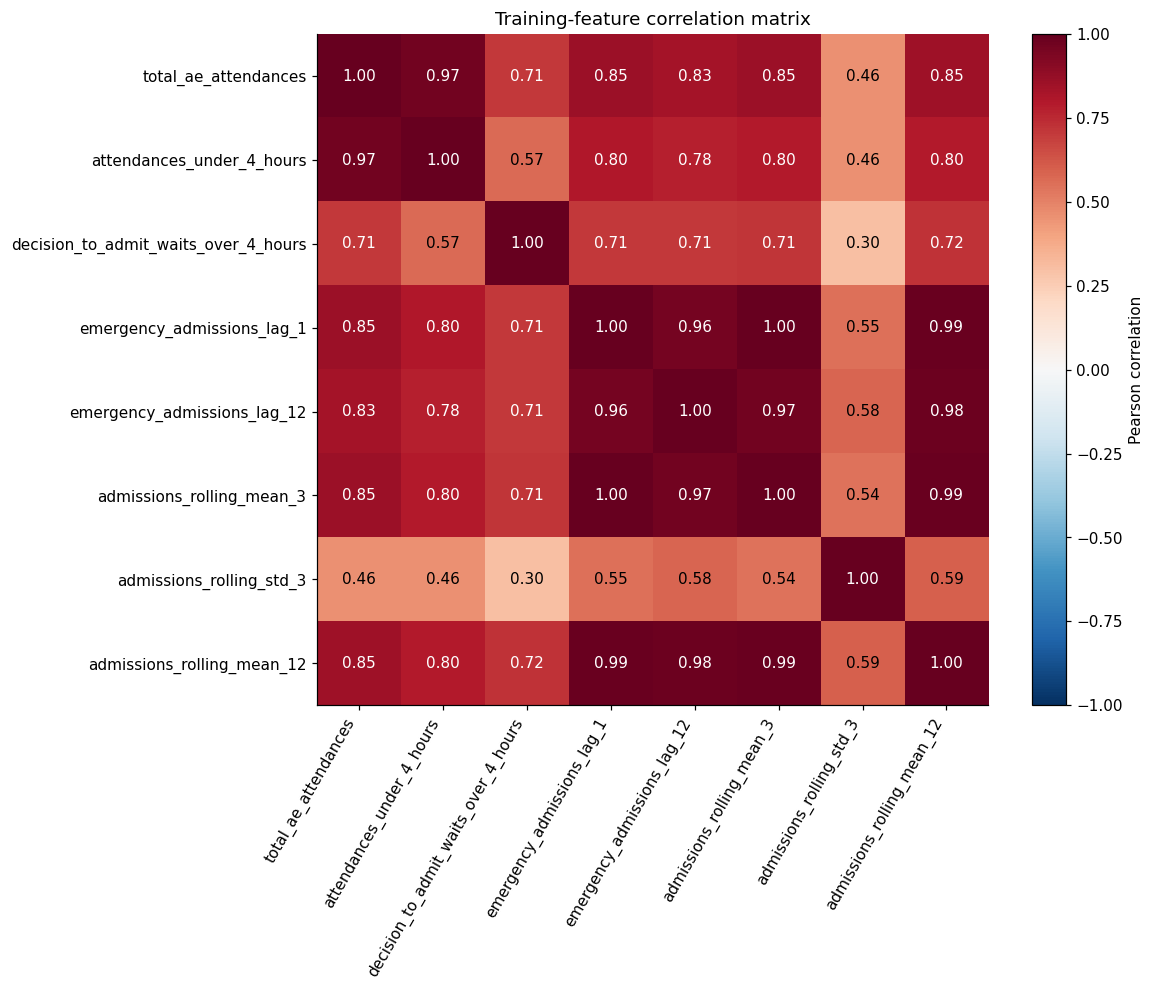

In [2]:
diag_cols = ['total_ae_attendances','attendances_under_4_hours','decision_to_admit_waits_over_4_hours',
             'emergency_admissions_lag_1','emergency_admissions_lag_12',
             'admissions_rolling_mean_3','admissions_rolling_std_3','admissions_rolling_mean_12']
diag_train = diag_data.loc[diag_period <= pd.Period(diag_config['training_target_end'])]
diag_corr = diag_train[diag_cols].corr()
fig, ax = plt.subplots(figsize=(11,9))
im = ax.imshow(diag_corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(diag_cols)), diag_cols, rotation=60, ha='right')
ax.set_yticks(range(len(diag_cols)), diag_cols)
for i in range(len(diag_cols)):
    for j in range(len(diag_cols)):
        v = diag_corr.iloc[i,j]
        ax.text(j,i,f'{v:.2f}',ha='center',va='center',color='white' if abs(v)>.65 else 'black')
ax.set_title('Training-feature correlation matrix')
fig.colorbar(im, ax=ax, label='Pearson correlation')
diag_save(fig, '01_feature_correlation_matrix')

### 2. Actual versus predicted and residual diagnostics
The diagonal is perfect prediction. Residual spread and extreme errors reveal weaknesses hidden by an overall score. Each point represents one provider-month.

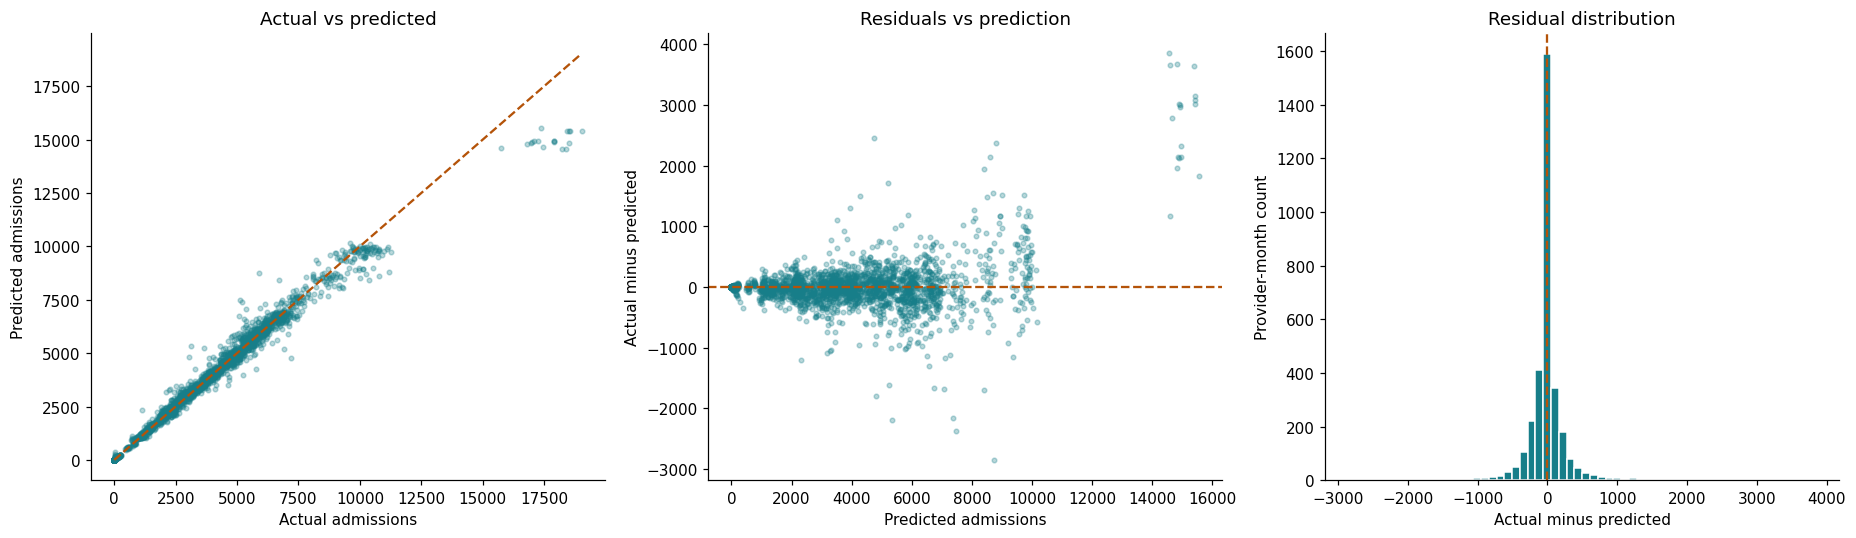

In [3]:
fig, axes = plt.subplots(1,3,figsize=(17,5))
axes[0].scatter(diag_test.actual,diag_test.prediction,s=9,alpha=.3,color='#177e89')
diag_limit = max(diag_test.actual.max(),diag_test.prediction.max())
axes[0].plot([0,diag_limit],[0,diag_limit],'--',color='#b45309')
axes[0].set(xlabel='Actual admissions',ylabel='Predicted admissions',title='Actual vs predicted')
axes[1].scatter(diag_test.prediction,diag_test.residual,s=9,alpha=.3,color='#177e89')
axes[1].axhline(0,color='#b45309',linestyle='--')
axes[1].set(xlabel='Predicted admissions',ylabel='Actual minus predicted',title='Residuals vs prediction')
axes[2].hist(diag_test.residual,bins=60,color='#177e89',edgecolor='white')
axes[2].axvline(0,color='#b45309',linestyle='--')
axes[2].set(xlabel='Actual minus predicted',ylabel='Provider-month count',title='Residual distribution')
diag_save(fig,'02_prediction_and_residual_diagnostics')

### 3. Monthly forecast totals and error trend
Totals include only eligible evaluated providers, not all NHS activity. Aggregation can hide cancelling provider-level errors; monthly WAPE sums absolute errors before dividing by admissions.

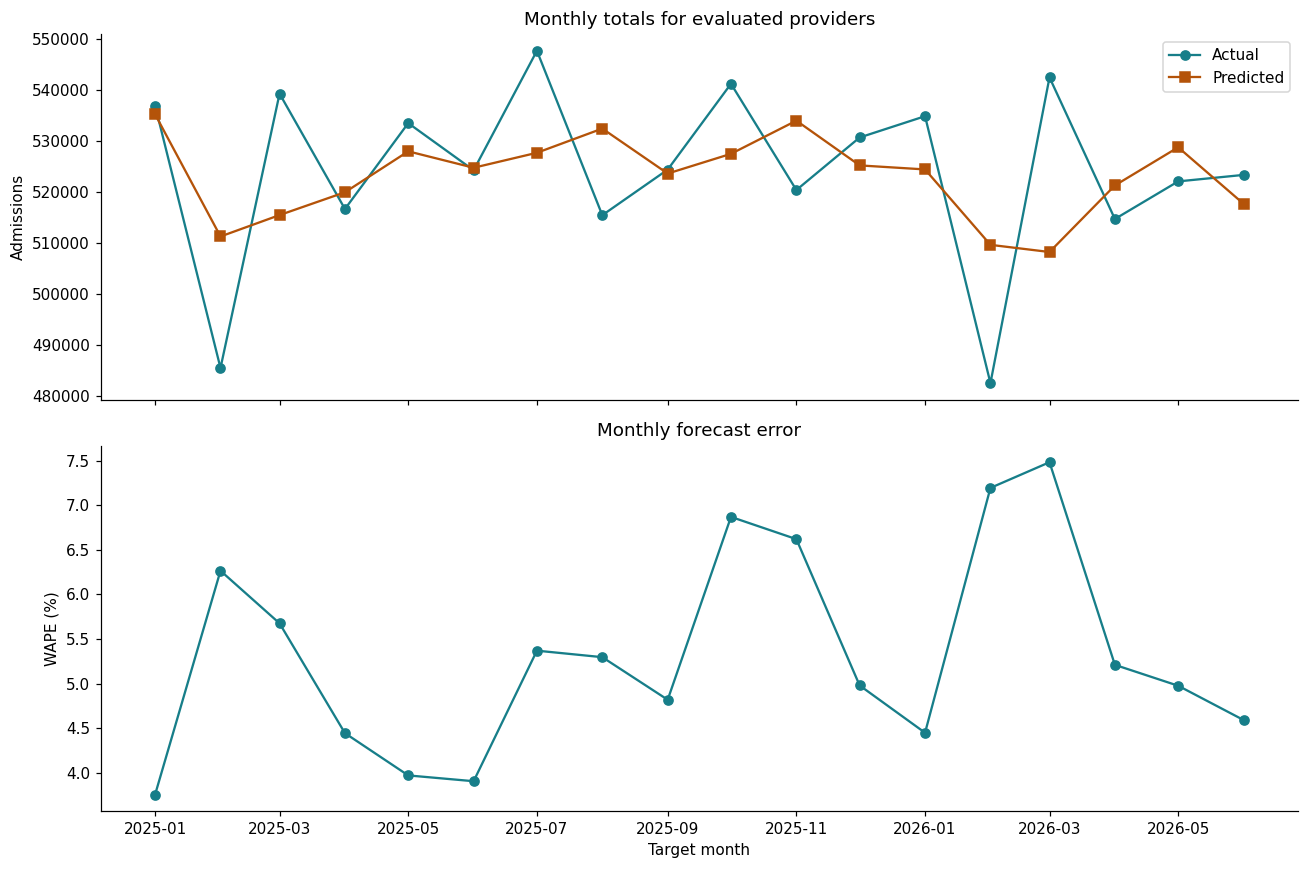

In [4]:
diag_month = diag_test.groupby('target_month')[['actual','prediction','absolute_error']].sum()
diag_month['wape'] = diag_month.absolute_error.div(diag_month.actual.replace(0,np.nan))*100
diag_dates = pd.to_datetime(diag_month.index)
fig, axes = plt.subplots(2,1,figsize=(12,8),sharex=True)
axes[0].plot(diag_dates,diag_month.actual,label='Actual',marker='o',color='#177e89')
axes[0].plot(diag_dates,diag_month.prediction,label='Predicted',marker='s',color='#b45309')
axes[0].set(ylabel='Admissions',title='Monthly totals for evaluated providers'); axes[0].legend()
axes[1].plot(diag_dates,diag_month.wape,marker='o',color='#177e89')
axes[1].set(ylabel='WAPE (%)',xlabel='Target month',title='Monthly forecast error')
diag_save(fig,'03_monthly_forecast_and_error')

### 4. Provider-by-month error matrix
The 15 providers with the highest actual admission totals are selected by volume, not by their error. Red indicates underprediction; blue indicates overprediction. Grey cells mean missing observations. Values are admission counts.

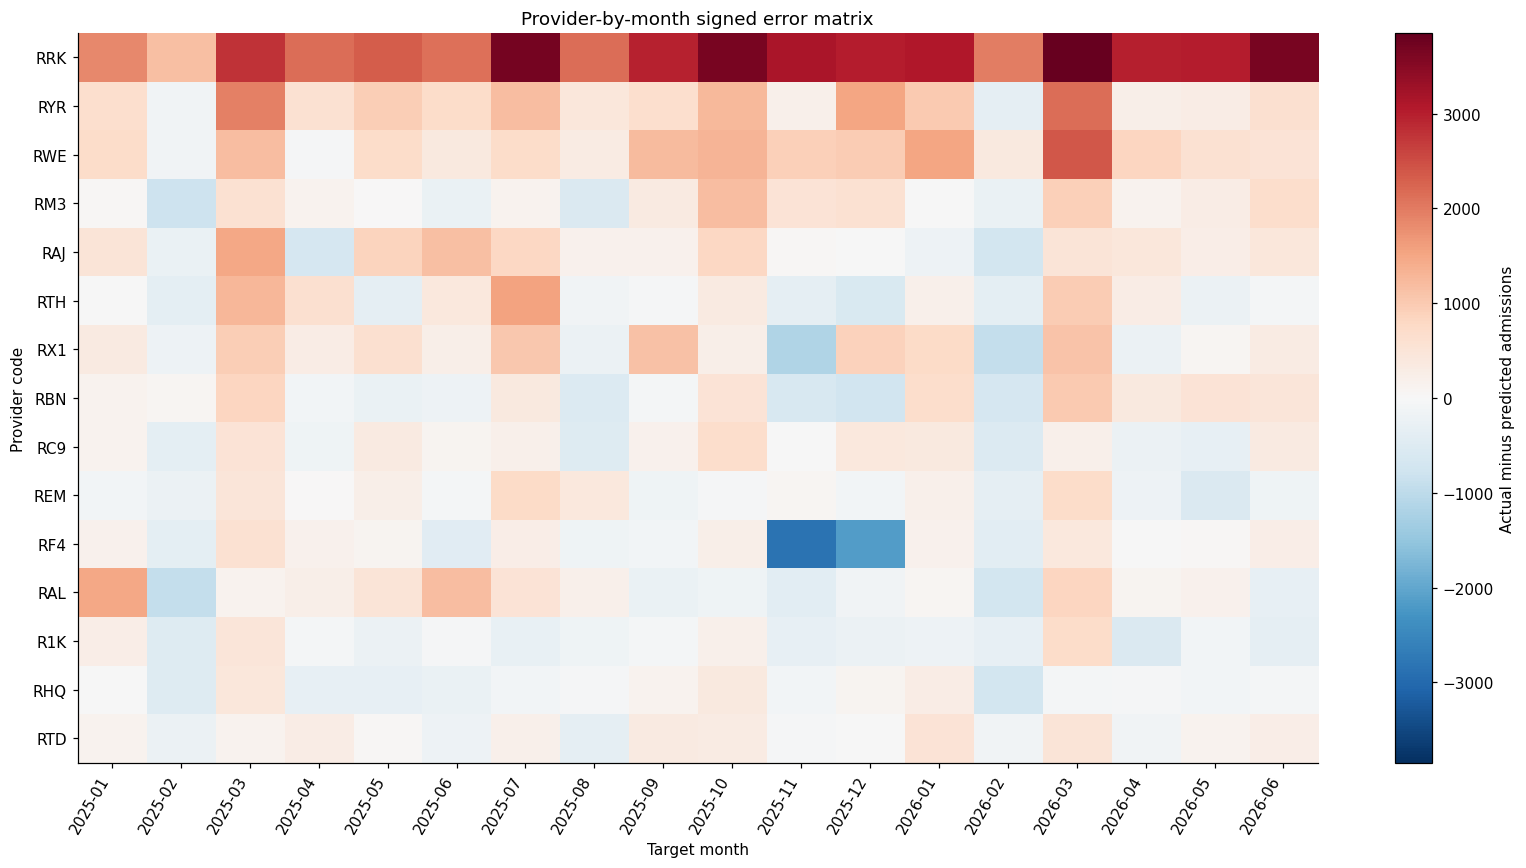

In [5]:
diag_top = diag_test.groupby('provider_code').actual.sum().nlargest(15).index
diag_matrix = diag_test[diag_test.provider_code.isin(diag_top)].pivot_table(index='provider_code',columns='target_month',values='residual',aggfunc='mean').reindex(diag_top)
fig, ax = plt.subplots(figsize=(15,8))
diag_cmap = plt.get_cmap('RdBu_r').copy(); diag_cmap.set_bad('#dddddd')
diag_max = max(float(np.nanmax(np.abs(diag_matrix.to_numpy(dtype=float, na_value=np.nan)))),1)
im = ax.imshow(np.ma.masked_invalid(diag_matrix.to_numpy(dtype=float, na_value=np.nan)),aspect='auto',cmap=diag_cmap,vmin=-diag_max,vmax=diag_max)
ax.set_xticks(range(len(diag_matrix.columns)),diag_matrix.columns,rotation=60,ha='right')
ax.set_yticks(range(len(diag_matrix)),diag_matrix.index)
ax.set(title='Provider-by-month signed error matrix',xlabel='Target month',ylabel='Provider code')
fig.colorbar(im,ax=ax,label='Actual minus predicted admissions')
diag_save(fig,'04_provider_month_error_matrix')

### 5. Validation benchmark comparison and metric matrix
Candidates are compared on validation data, which were used for model selection. Lower MAE, RMSE, and WAPE are better. Matrix colours are scaled separately per metric (0 = best, 1 = worst among candidates); annotations retain original units.

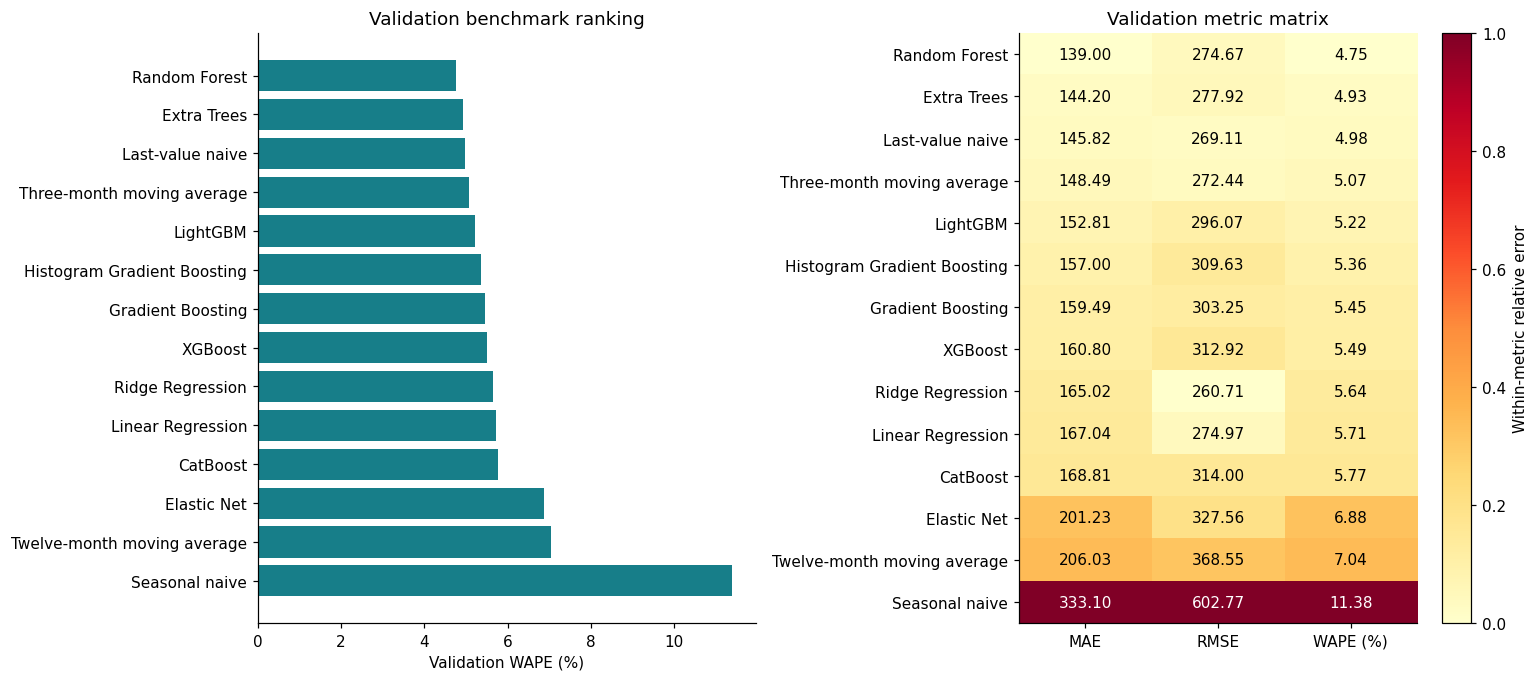

In [6]:
diag_bench = pd.read_csv(diag_art / 'benchmark_results.csv').dropna(subset=['wape','mae','rmse']).sort_values('wape')
diag_bench = diag_bench.set_index('model')
diag_metric = diag_bench[['mae','rmse','wape']].copy(); diag_metric['wape'] *= 100
diag_scaled = (diag_metric-diag_metric.min()).div((diag_metric.max()-diag_metric.min()).replace(0,1))
fig, axes = plt.subplots(1,2,figsize=(14,max(5,len(diag_bench)*.45)))
axes[0].barh(diag_bench.index,diag_bench.wape*100,color='#177e89'); axes[0].invert_yaxis()
axes[0].set(xlabel='Validation WAPE (%)',title='Validation benchmark ranking')
im = axes[1].imshow(diag_scaled,aspect='auto',cmap='YlOrRd',vmin=0,vmax=1)
axes[1].set_xticks([0,1,2],['MAE','RMSE','WAPE (%)'])
axes[1].set_yticks(range(len(diag_metric)),diag_metric.index)
for i in range(len(diag_metric)):
    for j in range(3):
        axes[1].text(j,i,f'{diag_metric.iloc[i,j]:.2f}',ha='center',va='center',color='white' if diag_scaled.iloc[i,j]>.65 else 'black')
axes[1].set_title('Validation metric matrix')
fig.colorbar(im,ax=axes[1],label='Within-metric relative error')
diag_save(fig,'05_benchmark_comparison_matrix')

### 6. Feature importance with variability
Permutation importance is the increase in validation MAE when a feature is shuffled. Error bars show standard deviation across repeats, not confidence intervals. Correlated features can share importance; values are not percentages.

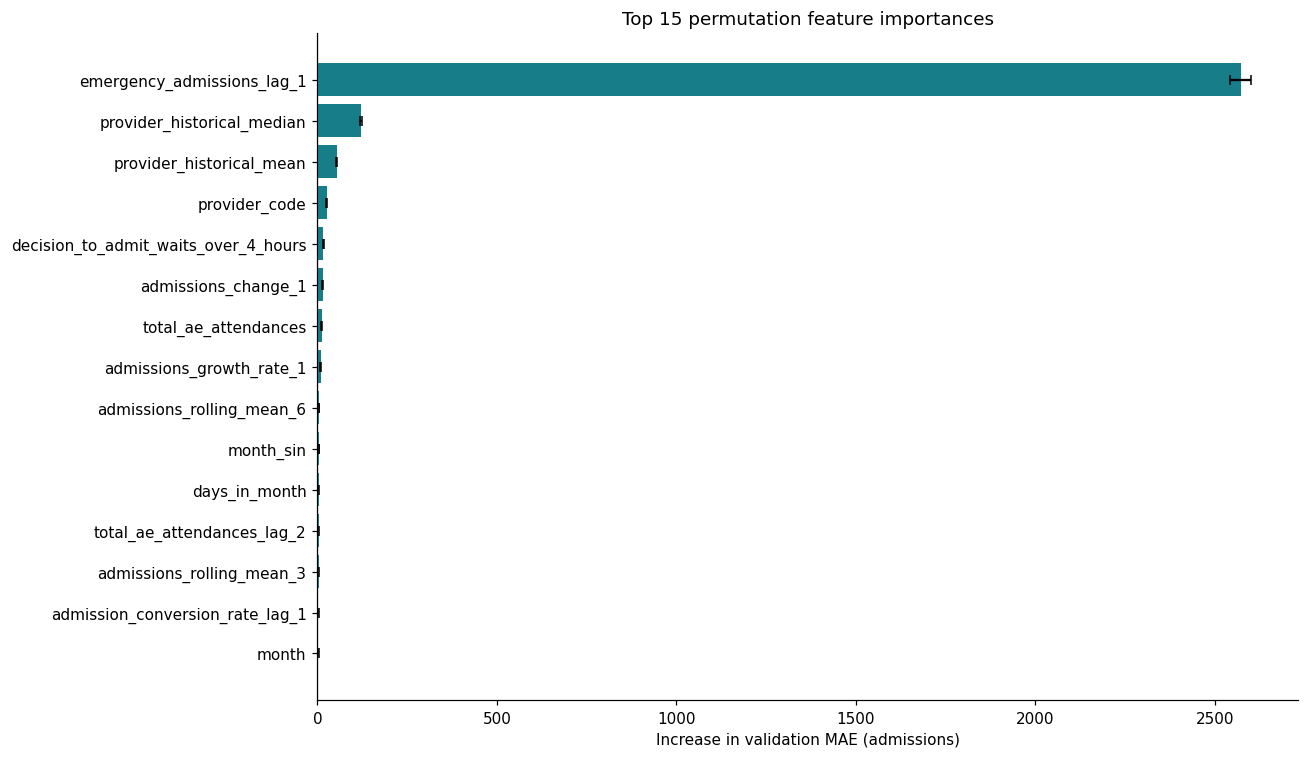

In [7]:
diag_importance = pd.read_csv(diag_art / 'feature_importance.csv').nlargest(15,'importance_mean').sort_values('importance_mean')
fig, ax = plt.subplots(figsize=(12,7))
ax.barh(diag_importance.feature,diag_importance.importance_mean,xerr=diag_importance.importance_std,color='#177e89',capsize=3)
ax.axvline(0,color='grey',linewidth=.8)
ax.set(xlabel='Increase in validation MAE (admissions)',title='Top 15 permutation feature importances')
diag_save(fig,'06_feature_importance')

### 7. Error by admission volume
Quartiles are descriptive groups based on observed test admissions, not deployable risk categories. WAPE uses the total absolute error divided by total actual admissions within each group.

,rows,actual_total,absolute_error,mae,bias,wape_pct
volume_group,,,,,,
"(-0.001, 1.0]",814,7.0,304.534545,0.374121,-0.374121,4350.493496
"(1.0, 2456.0]",804,963753.0,66223.181661,82.367141,-29.164103,6.871385
"(2456.0, 4833.5]",805,2953816.0,134766.404657,167.411683,-48.16325,4.562451
"(4833.5, 19035.0]",808,5519422.0,300465.576745,371.863338,103.163281,5.443787


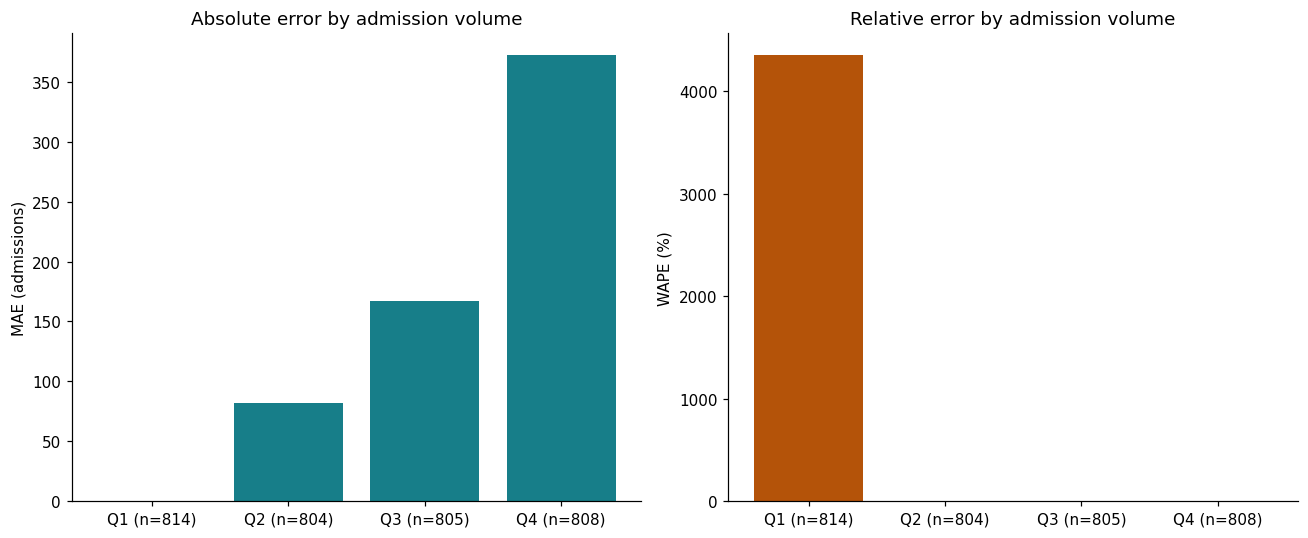

In [8]:
diag_test['volume_group'] = pd.qcut(diag_test.actual,4,duplicates='drop')
diag_volume = diag_test.groupby('volume_group',observed=True).agg(rows=('actual','size'),actual_total=('actual','sum'),absolute_error=('absolute_error','sum'),mae=('absolute_error','mean'),bias=('residual','mean'))
diag_volume['wape_pct'] = diag_volume.absolute_error.div(diag_volume.actual_total.replace(0,np.nan))*100
display(diag_volume)
fig, axes = plt.subplots(1,2,figsize=(12,5))
diag_labels = [f'Q{i+1} (n={int(n):,})' for i,n in enumerate(diag_volume.rows)]
axes[0].bar(diag_labels,diag_volume.mae,color='#177e89'); axes[0].set(ylabel='MAE (admissions)',title='Absolute error by admission volume')
axes[1].bar(diag_labels,diag_volume.wape_pct,color='#b45309'); axes[1].set(ylabel='WAPE (%)',title='Relative error by admission volume')
diag_save(fig,'07_volume_group_errors')

## 17 — Limitations and responsible use

Monthly reporting may be revised and schemas evolve. COVID-19 is an exceptional structural break. Provider mergers, closures, renaming, code changes, and reporting-footprint changes can interrupt series; no name-similarity merging is performed. Missing reports are not true zeros. Empirical intervals are uncertainty summaries, not guarantees. Performance must be monitored nationally and by provider.

> **This model is intended solely for research and hospital operations capacity-planning demonstrations. It forecasts aggregate provider-level emergency admissions and must not be used for individual patient, clinical, diagnostic, triage or treatment decisions.**